# wPINN con residual débil L2

Red neuronal informada por la física en **forma débil** para la ley de
conservación escalar en dos dimensiones espaciales

$$u_t + \partial_x H(u) + \partial_y H(u) = 0, \qquad (x,y) \in \Omega, \quad t \in [0,T],$$

con $u(x,y,0) = u_0(x,y)$.

Este notebook corre los **tres casos no lineales** del paper de Abreu, Florindo
y Lambert (ECCOMAS 2024) usando **únicamente la pérdida L2**, que es la pérdida
completa del paper: la desigualdad de Kruzhkov (L0, ec. 10), más la tasa de
entropía (L1, ec. 11), más la **difusión débil** de la ecuación 12 con
$\epsilon = 10^{-3}$. Las pérdidas L0 y L1 quedan **implementadas y
disponibles**, pero no se ejecutan: para usarlas basta pasar `residual_level=0`
o `residual_level=1` a `run_weak_pinn_case`.

| Caso | Flujo | Dominio | T | Exacta |
|---|---|---|---|---|
| rarefacción (ec. 17) | Burgers | $x \in [-5.5, 5.5]$, $y \in [-1.5, 1.5]$ | 2.5 | abanico entre $-1$ y $1$ |
| choque móvil (ec. 18) | Burgers | $x, y \in [-1, 1]$ | 0.5 | choque a velocidad $1/2$ |
| Riemann 2D (ec. 19) | Burgers | $x, y \in [0, 1]$ | $1/12$ | no hay |

**Por qué débil y no fuerte.** La solución de una ley de conservación no lineal
desarrolla choques en tiempo finito aunque el dato inicial sea suave. En un
choque $u$ no es derivable, así que el residual fuerte $u_t + H'(u)u_x$ no está
definido: lo que se minimiza ahí no significa nada. La forma débil integra
contra una función test y traslada las derivadas a ella, que sí es suave.

**Por qué entropía.** Pasar a la forma débil tiene un precio: deja de haber
unicidad. El dato de la rarefacción admite al menos dos soluciones débiles, el
abanico y el choque de expansión. La condición de entropía de Kruzhkov es la
desigualdad que selecciona la físicamente correcta.

**Qué añade L2 sobre L1.** Un término de difusión $\epsilon \Delta u$ escrito en
forma débil. La solución de entropía es el límite cuando $\epsilon \to 0$ de la
ley viscosa, así que meter una viscosidad pequeña empuja hacia ella por la vía
clásica. El paper argumenta además que este término **juega el papel del
ensamble** de De Ryck: estabiliza con una sola red lo que el ensamble estabiliza
promediando varias.

# Inicialización

Precisión, dispositivo y semillas. Todo el notebook trabaja en `float32`: en 2D
el costo lo domina el número de puntos de colocación, no el redondeo, y en GPUs
Blackwell la doble precisión está castigada en hardware.

In [1]:
import math
import time
from dataclasses import dataclass          # se usa en la celda 3 para describir cada problema
from typing import Callable, Optional      # idem: tipos de los campos del problema

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Precision por defecto de TODO tensor que creemos sin especificar dtype.
# float32 y no float64 porque:
#   (a) en 2D el costo lo domina el numero de puntos de colocacion, no el redondeo;
#   (b) en GPUs Blackwell (RTX 50xx) la doble precision esta castigada en hardware,
#       del orden de decenas de veces mas lenta que la simple.
# Si mas adelante el residual debil muestra ruido numerico inexplicable, subir a float64
# es el primer experimento a hacer.
torch.set_default_dtype(torch.float32)

# Dispositivo unico para todo el notebook. Se resuelve UNA vez y se reutiliza.
# Si se deja implicito terminamos con tensores en CPU y red en GPU, y torch aborta
# el entrenamiento con un error de dispositivo a mitad de camino.
COMPUTE_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_random_seed(seed: int = 0) -> None:
    """Fix every random source so a training run can be reproduced exactly.

    Two independent generators are in play: numpy drives anything we do with
    arrays outside the graph, torch drives weight initialisation and the
    Monte-Carlo sampling of collocation points.
    """
    # numpy: lo usamos poco, pero basta un np.random.rand en una grafica para
    # que dos corridas "identicas" dejen de serlo.
    np.random.seed(seed)
    # torch: cubre la inicializacion de pesos Y el muestreo de puntos, que es
    # la fuente de varianza mas fuerte en wPINN (rarefaccion vario entre 0.07 y 0.33
    # entre semillas en los experimentos 1D).
    torch.manual_seed(seed)


# Verificacion de entorno: debe decir algo como "2.14.0+cu128 cuda".
# Si dice "+cpu" la build de torch no trae kernels CUDA y hay que reinstalarla.
print(torch.__version__, COMPUTE_DEVICE)

2.11.0+cu128 cuda


# Perceptrón multicapa

Un solo bloque de red para los dos papeles del método: la **red solución**
$u_\theta(x,y,t)$ y la **red test** $\varphi_\eta(x,y,t)$. Nada en la clase sabe
de EDPs; lo único que cambia entre los dos usos son los argumentos del
constructor.

Las cotas de entrada sirven para normalizar a $[-1,1]$ antes de la primera capa.
Sin ellas, la rarefacción entra con $x$ del orden de 5 y satura las tangentes
hiperbólicas desde la primera iteración.

In [2]:
from typing import Sequence   # anchos de capa y cotas: listas o tuplas


class MLP(nn.Module):
    """Multi-layer perceptron: a fully connected feed-forward network R^n -> R^m.

    Deliberately problem-agnostic so it can be reused as a base block for any
    scientific machine learning task. Nothing in here knows about PDEs, space,
    time, or the number of coordinates. In this notebook it plays two roles:
    the solution network u_theta(x, y, t) and the adversarial test network
    phi_eta(x, y, t); only the constructor arguments change between the two.

    Parameters
    ----------
    n_input_features    : dimension of the input vector (3 for (x, y, t)).
    n_output_features   : dimension of the output vector (1 for a scalar law).
    hidden_layer_widths : neurons per hidden layer, one entry per layer
                          (paper: [20] * 6 for u, [10] * 4 for phi).
    activation          : activation module class placed after every hidden
                          layer. Default nn.Tanh, the usual choice for PINNs.
    input_lower_bounds  : optional, one value per input feature. Together with
                          input_upper_bounds rescales inputs to [-1, 1] before
                          the first layer. None disables the rescaling.
    input_upper_bounds  : see input_lower_bounds.
    weight_initialiser  : in-place initialiser applied to every linear layer's
                          weight matrix. Default Glorot / Xavier normal.
    """

    def __init__(
        self,
        n_input_features: int,
        n_output_features: int,
        hidden_layer_widths: Sequence[int],
        activation: type[nn.Module] = nn.Tanh,
        input_lower_bounds: Optional[Sequence[float]] = None,
        input_upper_bounds: Optional[Sequence[float]] = None,
        weight_initialiser: Callable[[torch.Tensor], torch.Tensor] = nn.init.xavier_normal_,
    ) -> None:
        super().__init__()

        # Las cotas son opcionales para que la clase sirva en problemas donde la
        # entrada ya viene normalizada. Se exige que vengan las dos o ninguna:
        # una sola no define un reescalamiento.
        if (input_lower_bounds is None) != (input_upper_bounds is None):
            raise ValueError("input_lower_bounds and input_upper_bounds must be given together")
        if input_lower_bounds is not None and len(input_lower_bounds) != n_input_features:
            raise ValueError("bounds must have one entry per input feature")

        # Cotas guardadas como buffers y NO como parámetros: viajan con la red a la
        # GPU (model.to(device)) y se guardan con state_dict, pero el optimizador
        # no las toca porque no son entrenables. register_buffer acepta None, así
        # que el atributo existe siempre y forward sólo pregunta si es None.
        self.register_buffer(
            "input_lower_bounds",
            None if input_lower_bounds is None else torch.tensor(input_lower_bounds),
        )
        self.register_buffer(
            "input_upper_bounds",
            None if input_upper_bounds is None else torch.tensor(input_upper_bounds),
        )

        # Se arma la lista [Linear, act, Linear, act, ..., Linear] recorriendo los
        # anchos de capa. Con una lista de anchos en vez de (ancho, n_capas) la
        # misma clase admite redes no uniformes, como una que se estrecha hacia
        # la salida, sin cambiar una línea.
        layer_input_widths = [n_input_features, *hidden_layer_widths]
        layers: list[nn.Module] = []
        for input_width, output_width in zip(layer_input_widths[:-1], layer_input_widths[1:]):
            layers += [nn.Linear(input_width, output_width), activation()]
        
        # Última capa sin activación: la salida puede tomar cualquier valor real
        # (por ejemplo -1 en la rarefacción); tanh la recortaría a (-1, 1).
        layers.append(nn.Linear(layer_input_widths[-1], n_output_features))
        self.network = nn.Sequential(*layers)

        # Inicialización de pesos. Por defecto Glorot (Xavier), que es la pensada
        # para tanh: mantiene la varianza de las activaciones de capa en capa, así
        # la red no arranca ni saturada (gradiente cero) ni colapsada en cero. La
        # de PyTorch por defecto (Kaiming uniforme con a=sqrt(5)) está pensada
        # para ReLU. Si alguien pasa activation=nn.ReLU debería pasar también
        # weight_initialiser=nn.init.kaiming_normal_; por eso es argumento.
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                weight_initialiser(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, input_points: torch.Tensor) -> torch.Tensor:
        """Evaluate the network on a batch of inputs.

        Parameters
        ----------
        input_points : tensor of shape (n_points, n_input_features).

        Returns
        -------
        tensor of shape (n_points, n_output_features).
        """
        # Reescalamiento afín de cada coordenada al intervalo [-1, 1] antes de la
        # primera capa, sólo si se dieron cotas. Sin esto, la rarefacción
        # (x en [-5.5, 5.5], t en [0, 2.5]) mete valores de magnitud 5 en tanh y
        # satura la primera capa desde la época cero. Con las cotas dentro de la
        # red, el resto del notebook trabaja en coordenadas físicas y nunca tiene
        # que acordarse de escalar.
        if self.input_lower_bounds is not None:
            input_points = (
                2.0 * (input_points - self.input_lower_bounds)
                / (self.input_upper_bounds - self.input_lower_bounds)
                - 1.0
            )
        return self.network(input_points)


def count_trainable_parameters(model: nn.Module) -> int:
    """Total number of scalar weights the optimiser will update."""
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

# El problema como dato

Un caso de uso completo en un solo objeto: flujos, dominio, horizonte temporal,
dato inicial, frontera, exacta si la hay, y el rango de valores que alcanza la
solución. Nada en la clase supone $d = 2$: la dimensión se lee del largo de las
cotas.

El rango `solution_value_range` cumple dos funciones distintas: fija la escala
de color de todas las figuras y fija el intervalo de donde salen las constantes
de Kruzhkov.

In [3]:
# Aliases de tipo. Todos los campos reciben tensores por lotes y devuelven
# (n_points, 1), para poder restarlos de la salida de la red sin reshape.
#   FluxFunction : H_i(u), recibe u de forma (n_points, 1).
#   InitialField : u_0(spatial_points), recibe (n_points, n_spatial_dimensions).
#   SpaceTimeField : u(spatial_points, time), recibe además time de forma (n_points, 1).
FluxFunction = Callable[[torch.Tensor], torch.Tensor]
InitialField = Callable[[torch.Tensor], torch.Tensor]
SpaceTimeField = Callable[[torch.Tensor, torch.Tensor], torch.Tensor]


@dataclass(frozen=True)
class ConservationLawProblem:
    """One instance of the scalar conservation law u_t + sum_i d/dx_i H_i(u) = 0
    on a box in R^d, for any number d of spatial dimensions.

    Nothing in the class assumes d = 2: the dimension is read from the length
    of the bounds, and every field receives the spatial coordinates as one
    tensor of shape (n_points, d) instead of separate x, y arguments. The four
    cases of the paper are d = 2 instances.

    Attributes
    ----------
    name                    : label used in plots and logs.
    fluxes                  : (H_1, ..., H_d), one flux per spatial direction.
    flux_derivatives        : (H_1', ..., H_d'), needed by the strong residual
                              u_t + sum_i H_i'(u) du/dx_i.
    spatial_lower_bounds    : (x_1_min, ..., x_d_min).
    spatial_upper_bounds    : (x_1_max, ..., x_d_max).
    final_time              : T, the time horizon; time runs over [0, T].
    initial_condition       : u_0(spatial_points).
    boundary_condition      : g(spatial_points, time) on the spatial boundary.
                              None when boundary_condition_type is "periodic".
    boundary_condition_type : "dirichlet" or "periodic", applied to every face.
    exact_solution          : u(spatial_points, time) when known, else None.
    solution_value_range    : (u_min, u_max) attained by the solution. Fixes
                              the colour scale of every plot and the range of
                              the Kruzhkov constants c in the wPINN.
    """

    name: str
    fluxes: tuple[FluxFunction, ...]
    flux_derivatives: tuple[FluxFunction, ...]
    spatial_lower_bounds: tuple[float, ...]
    spatial_upper_bounds: tuple[float, ...]
    final_time: float
    initial_condition: InitialField
    boundary_condition: Optional[SpaceTimeField]
    boundary_condition_type: str
    exact_solution: Optional[SpaceTimeField]
    solution_value_range: tuple[float, float]

    def __post_init__(self) -> None:
        # Se valida en construcción y no al usar, para que un error de dimensión
        # explote aquí con un mensaje claro y no dentro de autograd.
        n_dimensions = len(self.spatial_lower_bounds)
        if len(self.spatial_upper_bounds) != n_dimensions:
            raise ValueError("spatial_lower_bounds and spatial_upper_bounds must have the same length")
        if len(self.fluxes) != n_dimensions or len(self.flux_derivatives) != n_dimensions:
            raise ValueError("one flux and one flux derivative are needed per spatial dimension")
        if self.boundary_condition_type not in ("dirichlet", "periodic"):
            raise ValueError(f"unknown boundary_condition_type {self.boundary_condition_type!r}")
        if (self.boundary_condition is None) != (self.boundary_condition_type == "periodic"):
            raise ValueError("boundary_condition must be None exactly when the boundary is periodic")

    @property
    def n_spatial_dimensions(self) -> int:
        return len(self.spatial_lower_bounds)

    # Las cotas espacio-temporales (x_1, ..., x_d, t) son exactamente lo que pide
    # el MLP de la celda 2, así que se exponen como propiedades para no
    # reconstruir la tupla a mano cada vez que se crea una red.
    @property
    def space_time_lower_bounds(self) -> tuple[float, ...]:
        return (*self.spatial_lower_bounds, 0.0)

    @property
    def space_time_upper_bounds(self) -> tuple[float, ...]:
        return (*self.spatial_upper_bounds, self.final_time)

# Flujos

Burgers $H(u) = u^2/2$ para los tres casos de este notebook, y advección lineal
$H(u) = u$ para el cuarto caso del paper, que queda definido pero no se corre.

In [4]:
# --- Flujos ---------------------------------------------------------------
# Se definen como funciones con nombre y no como lambdas porque aparecen en los
# reprs y en los mensajes de error, y "burgers_flux" se lee mejor que "<lambda>".
def burgers_flux(u: torch.Tensor) -> torch.Tensor:
    """H(u) = u^2 / 2, the inviscid Burgers flux (paper eq. 16)."""
    return 0.5 * u**2


def burgers_flux_derivative(u: torch.Tensor) -> torch.Tensor:
    """H'(u) = u."""
    return u


def linear_advection_flux(u: torch.Tensor) -> torch.Tensor:
    """H(u) = u, unit-speed linear advection (paper eq. 20)."""
    return u


def linear_advection_flux_derivative(u: torch.Tensor) -> torch.Tensor:
    """H'(u) = 1, broadcast to the shape of u."""
    return torch.ones_like(u)

# Condiciones iniciales

Los datos de Riemann de los tres casos. Los dos primeros dependen sólo de $x$,
así que son efectivamente unidimensionales y entran por la misma ruta de código.

In [5]:
# Columnas de la matriz de coordenadas. Nombrarlas evita el "0" y "1" mágicos
# en cada campo y deja claro que el paper trabaja con (x, y) en ese orden.
X_COLUMN = 0
Y_COLUMN = 1


def coordinate_column(spatial_points: torch.Tensor, column: int) -> torch.Tensor:
    """Extract one coordinate as a column tensor of shape (n_points, 1)."""
    # El slice column:column+1 y no [:, column] preserva la segunda dimensión,
    # así el resultado se opera directamente con salidas de red (n_points, 1).
    return spatial_points[:, column : column + 1]


# --- Rarefacción (ec. 17) ---------------------------------------------------
def rarefaction_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = -1 for x <= 0, +1 for x > 0. Independent of y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= 0.0, -1.0, 1.0)


# --- Choque móvil (ec. 18) -------------------------------------------------
MOVING_SHOCK_LEFT_STATE = 1.0
MOVING_SHOCK_RIGHT_STATE = 0.0


def moving_shock_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = 1 for x <= 0, 0 for x > 0. Independent of y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= 0.0, MOVING_SHOCK_LEFT_STATE, MOVING_SHOCK_RIGHT_STATE)


# --- Riemann 2D (ec. 19) ---------------------------------------------------
def riemann_2d_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = 2 in the lower-left quadrant, 3 in the upper-right, 1 elsewhere."""
    x = coordinate_column(spatial_points, X_COLUMN)
    y = coordinate_column(spatial_points, Y_COLUMN)
    # El punto de corte es (0.25, 0.25) y no el centro del cuadrado. Con T = 1/12
    # y velocidad máxima H'(3) = 3, ninguna onda avanza más de 0.25, así que la
    # solución nunca toca el borde x = 1 ni y = 1 y las condiciones de frontera
    # tipo Dirichlet con el dato inicial son consistentes hasta T.
    lower_left = (x < 0.25) & (y < 0.25)
    upper_right = (x > 0.25) & (y > 0.25)
    return torch.where(lower_left, 2.0, torch.where(upper_right, 3.0, 1.0))


# --- Advección periódica (ec. 20-21) ---------------------------------------
def periodic_advection_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = sin^2(pi x) sin^2(pi y), smooth and 1-periodic in x and y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    y = coordinate_column(spatial_points, Y_COLUMN)
    return torch.sin(math.pi * x) ** 2 * torch.sin(math.pi * y) ** 2

# Condiciones de frontera

Dirichlet con el dato inicial congelado. Es válido mientras ninguna onda alcance
la frontera antes de $T$, lo que se verifica caso por caso en el docstring.

In [6]:
# --- Condición de frontera compartida por los tres casos de Burgers ---------
def initial_condition_frozen_in_time(initial_condition: InitialField) -> SpaceTimeField:
    """Build g(spatial_points, t) = u_0(spatial_points): the boundary keeps
    its initial value.

    Valid as long as no wave reaches the spatial boundary before T, which holds
    for the three Burgers cases: the rarefaction fan reaches |x| = 2.5 < 5.5,
    the shock reaches x = 0.25 < 1 and the 2D Riemann waves travel at most
    0.25 from (0.25, 0.25).
    """
    def boundary_condition(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
        return initial_condition(spatial_points)
    return boundary_condition

# Soluciones exactas

Para comparar. La rarefacción es el abanico $u = x/t$ recortado a $[-1,1]$; el
choque móvil viaja a la velocidad de Rankine-Hugoniot $s = 1/2$. El Riemann 2D
no tiene forma cerrada.

In [7]:
# --- Rarefacción (ec. 17) ---------------------------------------------------
def rarefaction_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Entropy solution: a fan u = x / t clipped to [-1, 1].

    Independent of y because the data is, so it is the 1D Burgers fan.
    """
    x = coordinate_column(spatial_points, X_COLUMN)
    # En t = 0 la división x / t es 0/0 o ±inf. Se protege con un t mínimo
    # positivo: para t < 1e-12, x / t queda fuera de [-1, 1] salvo en x = 0, así
    # que clamp devuelve ±1, que coincide con el dato inicial.
    safe_time = torch.clamp(time, min=1e-12)
    return torch.clamp(x / safe_time, min=-1.0, max=1.0)


# --- Choque móvil (ec. 18) -------------------------------------------------
# Velocidad de Rankine-Hugoniot del choque: s = (H(1) - H(0)) / (1 - 0) = 1/2.
# Se calcula desde el flujo y no se escribe 0.5 a mano para que la fórmula
# quede a la vista y para que cambie sola si alguien cambia el flujo.
MOVING_SHOCK_SPEED = (
    burgers_flux(torch.tensor(MOVING_SHOCK_LEFT_STATE)) - burgers_flux(torch.tensor(MOVING_SHOCK_RIGHT_STATE))
).item() / (MOVING_SHOCK_LEFT_STATE - MOVING_SHOCK_RIGHT_STATE)


def moving_shock_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """The jump travels to the right at the Rankine-Hugoniot speed 1/2."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= MOVING_SHOCK_SPEED * time, MOVING_SHOCK_LEFT_STATE, MOVING_SHOCK_RIGHT_STATE)


# --- Advección periódica (ec. 20-21) ---------------------------------------
def periodic_advection_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Pure translation: u(x, y, t) = u_0(x - t, y - t).

    No modulo is needed because sin^2 is already 1-periodic.
    """
    # Se resta t a TODAS las columnas porque la velocidad es (1, 1): el dato se
    # traslada en diagonal.
    return periodic_advection_initial_condition(spatial_points - time)

# Los cuatro problemas del paper

Los cuatro quedan definidos. Este notebook usa tres.

In [8]:
# --- Los cuatro problemas del paper -----------------------------------------
# El paper usa el mismo flujo en x y en y, así que se repite la función dos
# veces. Un problema anisótropo pasaría dos flujos distintos.
BURGERS_FLUXES_2D = (burgers_flux, burgers_flux)
BURGERS_FLUX_DERIVATIVES_2D = (burgers_flux_derivative, burgers_flux_derivative)

RAREFACTION_PROBLEM = ConservationLawProblem(
    name="rarefaction",
    fluxes=BURGERS_FLUXES_2D,
    flux_derivatives=BURGERS_FLUX_DERIVATIVES_2D,
    spatial_lower_bounds=(-5.5, -1.5),
    spatial_upper_bounds=(5.5, 1.5),
    final_time=2.5,
    initial_condition=rarefaction_initial_condition,
    boundary_condition=initial_condition_frozen_in_time(rarefaction_initial_condition),
    boundary_condition_type="dirichlet",
    exact_solution=rarefaction_exact_solution,
    solution_value_range=(-1.0, 1.0),
)

MOVING_SHOCK_PROBLEM = ConservationLawProblem(
    name="moving_shock",
    fluxes=BURGERS_FLUXES_2D,
    flux_derivatives=BURGERS_FLUX_DERIVATIVES_2D,
    # El paper escribe y en [1, 1]; es un typo, la figura muestra [-1, 1].
    spatial_lower_bounds=(-1.0, -1.0),
    spatial_upper_bounds=(1.0, 1.0),
    final_time=0.5,
    initial_condition=moving_shock_initial_condition,
    boundary_condition=initial_condition_frozen_in_time(moving_shock_initial_condition),
    boundary_condition_type="dirichlet",
    exact_solution=moving_shock_exact_solution,
    solution_value_range=(0.0, 1.0),
)

RIEMANN_2D_PROBLEM = ConservationLawProblem(
    name="riemann_2d",
    fluxes=BURGERS_FLUXES_2D,
    flux_derivatives=BURGERS_FLUX_DERIVATIVES_2D,
    spatial_lower_bounds=(0.0, 0.0),
    spatial_upper_bounds=(1.0, 1.0),
    final_time=1.0 / 12.0,
    initial_condition=riemann_2d_initial_condition,
    boundary_condition=initial_condition_frozen_in_time(riemann_2d_initial_condition),
    boundary_condition_type="dirichlet",
    # Sin exacta cerrada: aquí sólo se compara cualitativamente con la figura 3.
    exact_solution=None,
    solution_value_range=(1.0, 3.0),
)

PERIODIC_ADVECTION_PROBLEM = ConservationLawProblem(
    name="periodic_advection",
    fluxes=(linear_advection_flux, linear_advection_flux),
    flux_derivatives=(linear_advection_flux_derivative, linear_advection_flux_derivative),
    spatial_lower_bounds=(0.0, 0.0),
    spatial_upper_bounds=(1.0, 1.0),
    final_time=1.0,
    initial_condition=periodic_advection_initial_condition,
    # Periódica: no hay g, la condición es u(0, y, t) = u(1, y, t) y análoga en y.
    boundary_condition=None,
    boundary_condition_type="periodic",
    exact_solution=periodic_advection_exact_solution,
    solution_value_range=(0.0, 1.0),
)

# Los tres casos de este notebook

In [9]:
# Los tres casos no lineales del paper: los que tienen choques y, por tanto,
# los únicos donde la formulación débil con entropía de Kruzhkov cambia algo.
# La advección periódica (ec. 20-21) queda fuera porque su flujo es lineal y su
# solución es suave: no hay no unicidad que resolver. Para incluirla basta
# añadir PERIODIC_ADVECTION_PROBLEM a esta lista.
L2_STUDY_PROBLEMS = [RAREFACTION_PROBLEM, MOVING_SHOCK_PROBLEM, RIEMANN_2D_PROBLEM]

# Prueba de humo: donde hay exacta, en t = 0 debe coincidir con el dato inicial.
for problem in L2_STUDY_PROBLEMS:
    print(f"{problem.name:14s} d = {problem.n_spatial_dimensions}  T = {problem.final_time:.4g}  "
          f"u in {problem.solution_value_range}  exact: {problem.exact_solution is not None}")
    if problem.exact_solution is None:
        continue
    lower = torch.tensor(problem.spatial_lower_bounds)
    upper = torch.tensor(problem.spatial_upper_bounds)
    random_spatial_points = lower + (upper - lower) * torch.rand(1000, problem.n_spatial_dimensions)
    time_zero = torch.zeros(1000, 1)
    mismatch = (
        problem.exact_solution(random_spatial_points, time_zero) - problem.initial_condition(random_spatial_points)
    ).abs().max()
    print(f"{'':14s} max |exact(t=0) - u_0| = {mismatch:.1e}")

rarefaction    d = 2  T = 2.5  u in (-1.0, 1.0)  exact: True
               max |exact(t=0) - u_0| = 0.0e+00
moving_shock   d = 2  T = 0.5  u in (0.0, 1.0)  exact: True
               max |exact(t=0) - u_0| = 0.0e+00
riemann_2d     d = 2  T = 0.08333  u in (1.0, 3.0)  exact: False


# Espacio y tiempo

Convención de todo el notebook: un punto espacio-temporal es una fila
$(x_1,\dots,x_d,t)$ y el tiempo es **siempre** la última columna. Estas dos
funciones son el único lugar donde se asume ese orden.

In [10]:
# Convención de todo el notebook: un punto espacio-temporal es una fila
# (x_1, ..., x_d, t) y el tiempo es SIEMPRE la última columna. Estas dos
# funciones son el único lugar donde se asume ese orden.
TIME_COLUMN = -1


def split_space_time(space_time_points: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Split (n_points, d + 1) into spatial (n_points, d) and time (n_points, 1)."""
    return space_time_points[:, :TIME_COLUMN], space_time_points[:, TIME_COLUMN:]


def join_space_time(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Inverse of split_space_time: concatenate along the feature axis."""
    return torch.cat([spatial_points, time], dim=1)

# Muestreo uniforme en una caja

Monte Carlo y no malla: la pérdida es una esperanza sobre el dominio, y puntos
aleatorios uniformes la estiman sin la maldición de la dimensión.

In [11]:
def sample_uniform_in_box(
    lower_bounds: Sequence[float],
    upper_bounds: Sequence[float],
    n_points: int,
    device: torch.device = COMPUTE_DEVICE,
) -> torch.Tensor:
    """Draw n_points uniformly at random inside the box [lower, upper] in R^k.

    Returns a tensor of shape (n_points, k). Monte-Carlo sampling and not a
    grid because the PINN loss is an expectation over the domain, and uniform
    random points estimate it without the curse of dimensionality of a grid.
    """
    lower = torch.tensor(lower_bounds, device=device)
    upper = torch.tensor(upper_bounds, device=device)
    # torch.rand da U[0, 1); el mapa afín lo lleva a [lower, upper). Se genera
    # directamente en device para no pagar una copia CPU -> GPU por época.
    unit_samples = torch.rand(n_points, len(lower_bounds), device=device)
    return lower + (upper - lower) * unit_samples

# Puntos interiores, iniciales y de frontera

Tres conjuntos distintos para tres términos distintos de la pérdida. Los de
frontera se muestrean en toda la caja y luego se aplasta la coordenada de la
cara sobre su cota.

In [12]:
def sample_interior_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points in the open space-time box, where the PDE residual is enforced."""
    return sample_uniform_in_box(problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points)


def sample_initial_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points on the slice t = 0, where u = u_0 is enforced."""
    spatial_points = sample_uniform_in_box(problem.spatial_lower_bounds, problem.spatial_upper_bounds, n_points)
    time_zero = torch.zeros(n_points, 1, device=spatial_points.device)
    return join_space_time(spatial_points, time_zero)


def sample_boundary_points(
    problem: ConservationLawProblem, n_points: int
) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
    """Points on the lateral boundary (spatial faces x [0, T]).

    Returns (boundary_points, periodic_partner_points). For a Dirichlet
    problem the partner is None. For a periodic problem the partner has the
    same shape as boundary_points and each row is the same point with the
    face coordinate moved to the opposite face, so that the loss can enforce
    u(boundary) = u(partner).
    """
    n_faces = 2 * problem.n_spatial_dimensions
    # Se reparte el presupuesto por igual entre las 2d caras. Si n_points no es
    # múltiplo de 2d se pierde el residuo; es irrelevante frente a miles de puntos.
    n_points_per_face = n_points // n_faces

    boundary_points_per_face = []
    partner_points_per_face = []
    for dimension in range(problem.n_spatial_dimensions):
        for face_bound, opposite_bound in (
            (problem.spatial_lower_bounds[dimension], problem.spatial_upper_bounds[dimension]),
            (problem.spatial_upper_bounds[dimension], problem.spatial_lower_bounds[dimension]),
        ):
            # Se muestrea en toda la caja espacio-temporal y luego se "aplasta"
            # la coordenada de la cara sobre su cota. Es más simple que
            # construir la caja (d-1)-dimensional de cada cara a mano y da la
            # misma distribución uniforme sobre la cara.
            face_points = sample_uniform_in_box(
                problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points_per_face
            )
            face_points[:, dimension] = face_bound
            boundary_points_per_face.append(face_points)

            # El compañero periódico comparte todas las coordenadas (incluido t)
            # y sólo cambia la coordenada de la cara por la cota opuesta.
            partner_points = face_points.clone()
            partner_points[:, dimension] = opposite_bound
            partner_points_per_face.append(partner_points)

    boundary_points = torch.cat(boundary_points_per_face, dim=0)
    if problem.boundary_condition_type == "periodic":
        return boundary_points, torch.cat(partner_points_per_face, dim=0)
    return boundary_points, None

# Paquete de puntos de colocación

Un sorteo completo en un objeto, para pasarlo entero a la pérdida.

In [13]:
@dataclass(frozen=True)
class CollocationPoints:
    """One Monte-Carlo draw of every point set the loss needs.

    All tensors have d + 1 columns (x_1, ..., x_d, t) and live on the compute
    device. periodic_partner_points is None for Dirichlet problems.
    """

    interior_points: torch.Tensor
    initial_points: torch.Tensor
    boundary_points: torch.Tensor
    periodic_partner_points: Optional[torch.Tensor]


def sample_collocation_points(
    problem: ConservationLawProblem,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
) -> CollocationPoints:
    """Draw a fresh set of interior, initial and boundary points for one problem."""
    boundary_points, periodic_partner_points = sample_boundary_points(problem, n_boundary_points)
    return CollocationPoints(
        interior_points=sample_interior_points(problem, n_interior_points),
        initial_points=sample_initial_points(problem, n_initial_points),
        boundary_points=boundary_points,
        periodic_partner_points=periodic_partner_points,
    )

# Derivadas por autograd

Las derivadas de $u_\theta$ respecto a $(x,y,t)$ salen del grafo de
diferenciación automática, no de diferencias finitas. `create_graph=True` deja
el grafo vivo para poder derivar otra vez y para que el gradiente de la pérdida
atraviese este cálculo.

In [14]:
def gradient_with_respect_to_inputs(output: torch.Tensor, input_points: torch.Tensor) -> torch.Tensor:
    """d(output)/d(input) for a batch, returned with the shape of input_points.

    output has shape (n_points, 1) and input_points (n_points, k); the result
    is (n_points, k), column j being the partial derivative along input j.
    """
    # Truco estándar: la suma de las salidas tiene gradiente igual al jacobiano
    # fila a fila, porque cada salida depende SÓLO de su propia fila de entrada.
    # create_graph=True deja el grafo vivo para poder derivar otra vez (laplaciano)
    # y para que el gradiente de la pérdida atraviese este cálculo.
    return torch.autograd.grad(output.sum(), input_points, create_graph=True)[0]


def laplacian_in_space(gradient: torch.Tensor, input_points: torch.Tensor, n_spatial_dimensions: int) -> torch.Tensor:
    """Sum of second spatial derivatives d^2 u / dx_i^2, shape (n_points, 1).

    gradient is the output of gradient_with_respect_to_inputs; each column is
    differentiated once more and only the diagonal entry is kept.
    """
    laplacian = torch.zeros_like(gradient[:, :1])
    for dimension in range(n_spatial_dimensions):
        second_derivatives = gradient_with_respect_to_inputs(gradient[:, dimension : dimension + 1], input_points)
        laplacian = laplacian + second_derivatives[:, dimension : dimension + 1]
    return laplacian

# Penalizaciones

In [15]:
from dataclasses import field, replace   # listas por defecto en la historia; copias del presupuesto

# Una "penalización" reduce un tensor de discrepancias puntuales (n_points, 1)
# a un escalar. Ninguna pérdida sabe cuál se usa: se le pasa como argumento,
# así que cambiar de L2 a L1 en los términos de datos es cambiar un argumento.
PenaltyFunction = Callable[[torch.Tensor], torch.Tensor]


def mean_squared(values: torch.Tensor) -> torch.Tensor:
    """Mean of the squares: the Monte-Carlo estimate of the squared L2 norm."""
    return torch.mean(values**2)


def mean_absolute(values: torch.Tensor) -> torch.Tensor:
    """Mean of absolute values: the Monte-Carlo estimate of the L1 norm."""
    return torch.mean(values.abs())


def root_mean_squared(values: torch.Tensor) -> torch.Tensor:
    """Square root of mean_squared: same minimiser, gradients of different scale."""
    return torch.sqrt(mean_squared(values))

# Términos de datos

El dato inicial y la frontera. Son idénticos en la forma fuerte y en la débil:
lo único que distingue a las dos formulaciones es cómo se mide la ecuación.

In [16]:
def data_loss_terms(
    network: nn.Module,
    problem: ConservationLawProblem,
    points: CollocationPoints,
    penalty: PenaltyFunction = mean_squared,
) -> dict[str, torch.Tensor]:
    """Initial and boundary mismatch penalties, keys "initial" and "boundary".

    Identical for the strong and the weak formulation: only the PDE term
    changes between them. strong_pinn_loss_terms could call this too.
    """
    initial_spatial_points, _ = split_space_time(points.initial_points)
    initial_mismatch = network(points.initial_points) - problem.initial_condition(initial_spatial_points)

    if problem.boundary_condition_type == "periodic":
        # Periódica: la red debe valer lo mismo en las dos caras opuestas.
        boundary_mismatch = network(points.boundary_points) - network(points.periodic_partner_points)
    else:
        boundary_spatial_points, boundary_time = split_space_time(points.boundary_points)
        boundary_mismatch = network(points.boundary_points) - problem.boundary_condition(boundary_spatial_points, boundary_time)

    return {"initial": penalty(initial_mismatch), "boundary": penalty(boundary_mismatch)}

# La formulación débil y la entropía de Kruzhkov

**La idea.** $u$ es solución débil si para toda $\varphi$ suave de soporte
compacto

$$\int_0^T \int_\Omega \big( u\, \varphi_t + H(u)\cdot \nabla\varphi \big)\,dx\,dt = 0 .$$

Las derivadas están sobre $\varphi$, no sobre $u$, así que la identidad tiene
sentido aunque $u$ salte.

**El problema.** Esa identidad no determina a $u$. El dato de la rarefacción
admite el abanico y también el choque de expansión, y los dos la satisfacen.

**La condición de entropía.** Kruzhkov: para toda constante $c \in \mathbb{R}$ y
toda $\varphi \geq 0$ suave,

$$\int_0^T \int_\Omega \Big( |u - c|\, \varphi_t + Q(u,c) \cdot \nabla \varphi \Big)\, dx\, dt \;\geq\; 0,
\qquad Q_i(u,c) = \operatorname{sign}(u-c)\,\big(H_i(u) - H_i(c)\big).$$

La familia $|u-c|$ son las entropías de Kruzhkov y $Q$ son sus flujos. La
solución que cumple esto para todo $c$ es única.

**Cómo se vuelve una pérdida.** Siguiendo a De Ryck et al. se integra por partes
sólo en el espacio, dejando la derivada temporal sobre $|u-c|$:

$$R(c) \;=\; |D| \cdot \mathbb{E}\Big[\, \varphi\, \operatorname{sign}(u-c)\, u_t \;-\; \sum_i Q_i\, \partial_i \varphi \,\Big].$$

Una solución de entropía da $R(c) \leq 0$ para toda $\varphi \geq 0$ y toda $c$.
Lo que se castiga es la violación, es decir la parte positiva:

$$J(c) \;=\; \frac{\operatorname{ReLU}\big(R(c)\big)^2}{\|\nabla_x \varphi\|^2_{L^2}} .$$

Tres decisiones de diseño que valen la pena entender:

1. **Por qué $\varphi \geq 0$.** La condición de Kruzhkov es una *desigualdad*
   probada contra funciones test no negativas. Si $\varphi$ pudiera cambiar de
   signo, $-\varphi$ convertiría la desigualdad en igualdad y la pérdida
   castigaría la disipación legítima de un choque físico. Se impone con
   `softplus`.
2. **Por qué se divide por $\|\nabla_x\varphi\|^2$.** Sin normalizar, la red
   adversaria maximiza simplemente escalando $\varphi$: el residual crece sin
   cota sin decir nada sobre $u$. El cociente es la norma $H^{-1}$ discreta y es
   invariante por reescalamiento de $\varphi$.
3. **Por qué el máximo sobre $c$ y no el promedio.** La desigualdad debe valer
   para **toda** $c$, así que la peor es la que manda. En los experimentos 1D,
   promediar sobre $c$ diluía las constantes extremas (las que reproducen la
   ecuación) y rompía el choque.

El conjunto de constantes $c$ se extiende un 25 % por fuera del rango de $u$ a
propósito: con $c < \min u$ el residual de entropía **es** el residual de la
ecuación, y con $c > \max u$ es su negativo. Pedir que ambos extremos se anulen
equivale a imponer la EDP; las $c$ interiores añaden la desigualdad que descarta
el choque de expansión.

## Los dos términos que L2 añade sobre L0

**Primero, la tasa de entropía (L1, ec. 11).** La desigualdad de arriba se
prueba contra una función test: sólo controla la entropía **donde la adversaria
decide mirar**. La ecuación 11 añade una condición global, sin $\varphi$:

$$|D| \cdot \mathbb{E}\big[\, \operatorname{sign}(u-c)\, u_t \,\big]
\;=\; \int_\Omega \big( |u(x,T) - c| - |u_0(x) - c| \big)\, dx,$$

la entropía de Kruzhkov **neta producida** entre $0$ y $T$. Una solución de
entropía no produce entropía, así que ese número debe ser $\leq 0$.

**Segundo, la difusión débil (L2, ec. 12).** Se parte de la ley viscosa

$$u_t + \nabla \cdot H(u) - \epsilon \Delta u = 0,$$

cuya solución converge a la de entropía cuando $\epsilon \to 0$. Al probarla
contra $\varphi$ e integrar por partes, el laplaciano cambia de signo y pasa a
la función test:

$$-\epsilon \int \Delta u \, \varphi \;=\; +\epsilon \int \nabla u \cdot \nabla \varphi .$$

El factor $\operatorname{sign}(u-c)$ lo convierte en la difusión de $|u-c|$. El
resultado es

$$R_2(c) \;=\; R_1(c) \;+\; \epsilon\, |D| \cdot \mathbb{E}\big[\, \operatorname{sign}(u-c)\, \nabla u \cdot \nabla\varphi \,\big].$$

Dos observaciones que conviene tener claras:

- El signo es $+$ y no $-$ porque el $L_0$ de este notebook no lleva el menos
  global que el paper pone delante de su integral; es la misma ecuación con la
  convención de signo cambiada.
- Este término **sí** necesita el gradiente espacial de $u$, que los otros dos
  no usan. No cuesta nada extra: ya se calculó para la derivada temporal.

# Red de funciones test

La función test no se escoge de un banco fijo: es una **segunda red neuronal**
que se entrena para encontrar la peor violación de la entropía. De ahí el
nombre de adversaria.

Su estructura es $\varphi = \text{ventana}(x) \cdot \text{rango}(\xi(x,t))$, con
dos ganchos intercambiables: el rango actúa sobre el valor (impone el signo) y
la ventana sobre el dominio (impone dónde se anula).

In [17]:
import torch.nn.functional as functional   # softplus, una de las transformaciones de rango

# Dos "ganchos" definen la estructura de phi a partir del MLP interno xi:
#   phi(x, t) = window(x, t) * range_transform(xi(x, t))
# range_transform actúa sobre el VALOR (impone signo, cota, etc.);
# window actúa sobre el DOMINIO (dónde phi se anula). Cualquiera puede ser None.
# El paper no impone ninguno; De Ryck usa softplus + campana polinómica.
RangeTransform = Callable[[torch.Tensor], torch.Tensor]
WindowFunction = Callable[[torch.Tensor], torch.Tensor]


class TestFunctionNetwork(nn.Module):
    """Adversarial test function phi(x, t) of the weak formulation.

        phi(x, t) = window(x, t) * range_transform(xi(x, t))

    xi is a plain MLP (the paper: 4 layers of 10 neurons). range_transform
    shapes the values (e.g. softplus for phi > 0) and window shapes the
    support (e.g. a bump vanishing on the spatial boundary). None for both
    reproduces the paper literally. Any callable with the right signature
    can be plugged in, so alternative constraints are a one-line change.

    Parameters
    ----------
    problem             : gives the box and the input dimension d + 1.
    hidden_layer_widths : layers of the inner MLP.
    range_transform     : (n_points, 1) -> (n_points, 1), applied to xi. None = identity.
    window              : (n_points, d + 1) -> (n_points, 1), multiplies the result. None = 1.
    """

    def __init__(
        self,
        problem: ConservationLawProblem,
        hidden_layer_widths: Sequence[int],
        range_transform: Optional[RangeTransform] = None,
        window: Optional[WindowFunction] = None,
    ) -> None:
        super().__init__()
        self.range_transform = range_transform
        self.window = window
        self.inner_network = MLP(
            n_input_features=problem.n_spatial_dimensions + 1,
            n_output_features=1,
            hidden_layer_widths=hidden_layer_widths,
            input_lower_bounds=problem.space_time_lower_bounds,
            input_upper_bounds=problem.space_time_upper_bounds,
        )

    def forward(self, space_time_points: torch.Tensor) -> torch.Tensor:
        test_values = self.inner_network(space_time_points)
        if self.range_transform is not None:
            test_values = self.range_transform(test_values)
        if self.window is not None:
            test_values = self.window(space_time_points) * test_values
        return test_values

    def reset_parameters(self) -> None:
        """Re-draw the inner weights. De Ryck (Algorithm 1) restarts the
        adversary every epoch so it does not get stuck in a stale maximum."""
        for layer in self.inner_network.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

# Transformaciones de rango

In [18]:
# softplus(z) = ln(1 + e^z) > 0, suave, derivada nunca nula. Es la elección
# de De Ryck para phi >= 0: la condición de Kruzhkov es una desigualdad
# probada contra phi >= 0; con phi de signo libre, -phi la convierte en
# igualdad y la pérdida castiga la disipación legítima de un choque físico.
positive_by_softplus: RangeTransform = functional.softplus


def positive_by_square(values: torch.Tensor) -> torch.Tensor:
    """phi = xi^2 >= 0. Can touch zero, unlike softplus; gradient vanishes there."""
    return values**2


def bounded_by_tanh(values: torch.Tensor) -> torch.Tensor:
    """phi in (-1, 1). Caps the amplitude instead of the sign, an alternative
    to the H^-1 normalisation for taming the adversary."""
    return torch.tanh(values)

# Ventanas de soporte

In [19]:
def polynomial_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """omega(x) = prod_i 4 (x_i - a_i)(b_i - x_i) / (b_i - a_i)^2: 1 at the
    centre of the box, 0 on every spatial face. Ignores t."""
    lower = torch.tensor(problem.spatial_lower_bounds, device=COMPUTE_DEVICE)
    upper = torch.tensor(problem.spatial_upper_bounds, device=COMPUTE_DEVICE)
    extents = upper - lower

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        spatial_points, _ = split_space_time(space_time_points)
        # Se anula en la frontera espacial: justifica integrar por partes en x
        # sin términos de borde. El 4/(b-a)^2 normaliza el máximo a 1.
        bump_per_axis = 4.0 * (spatial_points - lower) * (upper - spatial_points) / extents**2
        return torch.prod(bump_per_axis, dim=1, keepdim=True)

    return window


def sine_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """omega(x) = prod_i sin(pi (x_i - a_i) / (b_i - a_i)): same zeros as the
    polynomial bump but flatter near the centre, so phi is less concentrated."""
    lower = torch.tensor(problem.spatial_lower_bounds, device=COMPUTE_DEVICE)
    upper = torch.tensor(problem.spatial_upper_bounds, device=COMPUTE_DEVICE)
    extents = upper - lower

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        spatial_points, _ = split_space_time(space_time_points)
        return torch.prod(torch.sin(math.pi * (spatial_points - lower) / extents), dim=1, keepdim=True)

    return window


def space_time_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """Polynomial bump in space times t (T - t): phi also vanishes at t = 0 and
    t = T, the choice when integrating by parts in time as well."""
    spatial_window = polynomial_bump_window(problem)
    final_time = problem.final_time

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        _, time = split_space_time(space_time_points)
        return spatial_window(space_time_points) * 4.0 * time * (final_time - time) / final_time**2

    return window

# Constantes de Kruzhkov

In [20]:
def kruzhkov_constants(problem: ConservationLawProblem, n_constants: int, margin_fraction: float = 0.25) -> torch.Tensor:
    """Grid of constants c for the Kruzhkov entropies |u - c|, shape (1, n_constants).

    Spans the solution range extended by margin_fraction on both sides.
    """
    u_min, u_max = problem.solution_value_range
    margin = margin_fraction * (u_max - u_min)
    # El conjunto DEBE salirse del rango de u por los dos lados: con c < min u
    # el residual de entropía es el residual de la ecuación, y con c > max u es
    # su negativo. Pedir ReLU = 0 en ambos extremos equivale a imponer la EDP;
    # los c interiores añaden la desigualdad que descarta el choque de expansión.
    return torch.linspace(u_min - margin, u_max + margin, n_constants, device=COMPUTE_DEVICE).reshape(1, -1)


def space_time_volume(problem: ConservationLawProblem) -> float:
    """|Omega| * T, the constant that turns a Monte-Carlo mean into an integral."""
    spatial_volume = math.prod(
        upper - lower for lower, upper in zip(problem.spatial_lower_bounds, problem.spatial_upper_bounds)
    )
    return spatial_volume * problem.final_time

# Entradas del residual débil

Todo lo que un término del residual puede necesitar, evaluado una sola vez en
los puntos interiores. Las cantidades derivadas son propiedades para no
recalcularlas en cada término.

In [21]:
def evaluate_with_gradient(network: nn.Module, points: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Return (values, gradient) of a scalar network at the points.

    values has shape (n_points, 1) and gradient (n_points, d + 1). Used for
    both the solution network and the test network.
    """
    points = points.clone().requires_grad_(True)
    values = network(points)
    return values, gradient_with_respect_to_inputs(values, points)


@dataclass(frozen=True)
class WeakResidualInputs:
    """Everything a weak residual term may need, evaluated at the interior points.

    solution, test_values      : (n_points, 1)
    solution_gradient, test_gradient : (n_points, d + 1), time in the last column
    constants                  : (1, n_constants), the Kruzhkov grid
    """

    problem: ConservationLawProblem
    solution: torch.Tensor
    solution_gradient: torch.Tensor
    test_values: torch.Tensor
    test_gradient: torch.Tensor
    constants: torch.Tensor

    # Cantidades derivadas que usan varios términos, calculadas una vez.
    @property
    def sign_u_minus_c(self) -> torch.Tensor:
        """sign(u - c), shape (n_points, n_constants) by broadcasting."""
        return torch.sign(self.solution - self.constants)

    @property
    def time_derivative(self) -> torch.Tensor:
        return self.solution_gradient[:, TIME_COLUMN:]

    @property
    def spatial_solution_gradient(self) -> torch.Tensor:
        return self.solution_gradient[:, : self.problem.n_spatial_dimensions]

    @property
    def spatial_test_gradient(self) -> torch.Tensor:
        return self.test_gradient[:, : self.problem.n_spatial_dimensions]

# Los términos del residual: L0, L1 y L2

Un término del residual es cualquier función de las entradas que devuelva el
integrando puntual. El residual es la media de la suma de los términos elegidos,
así que **L0, L1 y L2 del paper son simplemente listas de términos**.

- `kruzhkov_term` es L0 (ec. 10): la desigualdad de entropía. **Primer
  sumando de L2.**
- `entropy_rate_term` es lo que L1 añade (ec. 11): la tasa de entropía total.
  **Segundo sumando de L2.**
- `weak_diffusion_term` es lo que L2 añade (ec. 12): difusión débil con
  $\epsilon = 10^{-3}$. **El término que distingue a este notebook.**

Los tres están implementados. `paper_loss_terms(level)` arma la lista.

In [22]:
# Un término del residual débil es cualquier función de las entradas que
# devuelva el integrando puntual, forma (n_points, n_constants). El residual
# es |D| veces la media de la suma de los términos elegidos. Así L0, L1 y L2
# del paper son listas de términos, y un término nuevo es una función nueva.
WeakResidualTerm = Callable[[WeakResidualInputs], torch.Tensor]


def kruzhkov_term(inputs: WeakResidualInputs) -> torch.Tensor:
    """L0, paper eq. (10): phi * s * u_t - sum_i Q_i * d_i phi, Q_i = s (H_i(u) - H_i(c)).

    Integrated by parts in space only; the time derivative stays on |u - c|
    as in De Ryck. Non-positive for an entropy solution and any phi >= 0.
    """
    sign = inputs.sign_u_minus_c
    entropy_flux_divergence = torch.zeros_like(sign)
    for dimension, flux in enumerate(inputs.problem.fluxes):
        entropy_flux = sign * (flux(inputs.solution) - flux(inputs.constants))
        entropy_flux_divergence = entropy_flux_divergence + entropy_flux * inputs.test_gradient[:, dimension : dimension + 1]
    return inputs.test_values * sign * inputs.time_derivative - entropy_flux_divergence


def entropy_rate_term(inputs: WeakResidualInputs) -> torch.Tensor:
    """L1 - L0, paper eq. (11): d/dt of the total Kruzhkov entropy, s * u_t.

    Integrated over space-time it equals int |u(T) - c| - |u_0 - c| dx, the
    net entropy produced; an entropy solution does not produce any.
    """
    # Sin phi: es la tasa de la entropía total, no un residual probado contra
    # una función test. Por eso el paper lo escribe fuera de la integral con phi.
    return inputs.sign_u_minus_c * inputs.time_derivative


def weak_diffusion_term(diffusion_coefficient: float) -> WeakResidualTerm:
    """L2 - L1, paper eq. (12): + eps * s * grad u . grad phi.

    The viscous law u_t + div H(u) - eps Lap u = 0 tested against phi and
    integrated by parts turns -eps Lap u into +eps grad u . grad phi; the
    sign s makes it the diffusion of |u - c|. The paper writes it with a
    minus because its L0 carries a global minus in front.
    """
    def term(inputs: WeakResidualInputs) -> torch.Tensor:
        return diffusion_coefficient * inputs.sign_u_minus_c * torch.sum(
            inputs.spatial_solution_gradient * inputs.spatial_test_gradient, dim=1, keepdim=True
        )
    return term


# Las tres pérdidas del paper como listas de términos. Cualquier otra
# combinación, o un término propio, se arma igual.
def paper_loss_terms(level: int, diffusion_coefficient: float = 1e-3) -> list[WeakResidualTerm]:
    """L0, L1 or L2 of the paper (eqs. 10-12) as a list of residual terms."""
    terms: list[WeakResidualTerm] = [kruzhkov_term]
    if level >= 1:
        terms.append(entropy_rate_term)
    if level >= 2:
        terms.append(weak_diffusion_term(diffusion_coefficient))
    return terms

# Residual débil y agregación sobre c

In [23]:
def weak_entropy_residual(
    inputs: WeakResidualInputs,
    residual_terms: Sequence[WeakResidualTerm],
    signed: bool = False,
) -> tuple[torch.Tensor, torch.Tensor]:
    """R(c) = |D| mean( sum of the chosen terms ) for every constant c at once,
    and its normalised penalty J(c) = ReLU(R(c))^2 / ||grad phi||^2 (eq. 13).

    Returns (J, R), both of shape (n_constants,). With signed=True, J is
    R |R| / ||grad phi||^2: same value where R > 0, negative where R < 0, so
    the adversary keeps a gradient before it finds any violation.
    """
    volume = space_time_volume(inputs.problem)
    integrand = sum(term(inputs) for term in residual_terms)
    residual_per_constant = volume * torch.mean(integrand, dim=0)

    # Normalización H^-1 discreta: sin ella la adversaria maximiza escalando
    # phi, y el residual crece sin cota sin decir nada sobre u.
    test_gradient_norm_squared = volume * torch.mean(torch.sum(inputs.spatial_test_gradient**2, dim=1))
    small_number_to_avoid_division_by_zero = 1e-12
    if signed:
        numerator = residual_per_constant * residual_per_constant.abs()
    else:
        numerator = torch.relu(residual_per_constant) ** 2
    return numerator / (test_gradient_norm_squared + small_number_to_avoid_division_by_zero), residual_per_constant


def aggregate_over_constants(penalties_per_constant: torch.Tensor, mode: str = "max") -> torch.Tensor:
    """Collapse J(c) over the grid of constants into one scalar.

    "max" is De Ryck's remark 4.3: the entropy condition must hold for every
    c, so the worst one drives the loss. "mean" is gentler but, in the 1D
    experiments, averaging let the shock smear out; keep "max" by default.
    """
    if mode == "max":
        return penalties_per_constant.max()
    if mode == "mean":
        return penalties_per_constant.mean()
    raise ValueError(f"unknown aggregation mode {mode!r}")

# Proceso de entrenamiento

Aquí está el corazón del método. Lo que sigue describe exactamente lo que hacen
las dos celdas siguientes.

## Qué se optimiza

No es una minimización, es un **problema de punto silla** (min-max):

$$\min_{\theta} \; \max_{\eta} \; \Big[ \underbrace{\max_{c}\, J\big(u_\theta, \varphi_\eta, c\big)}_{\text{residual débil}} \;+\; \lambda \underbrace{\big( \mathcal{L}_{\text{inicial}} + \mathcal{L}_{\text{frontera}} \big)}_{\text{datos}} \Big]$$

- $\theta$ son los pesos de la red solución, que **minimiza**.
- $\eta$ son los pesos de la red test, que **maximiza**: busca la función test
  que más delata a la solución actual.
- $\lambda$ es `boundary_weight`. Con $\lambda = 10$ los datos pesan diez veces
  más que la ecuación, que es lo que impide la solución trivial.

La interpretación es un juego: la red test es un examinador que busca la peor
pregunta, y la red solución es un estudiante que debe responder bien a la peor
pregunta posible. El equilibrio es una solución que ningún examinador puede
delatar.

## Anatomía de una época

Cada época ejecuta cuatro pasos en este orden:

**1. Remuestreo de puntos (opcional).** Con `resample_every_n_epochs=None`, que
es el valor por defecto y el del paper, se sortean los puntos **una sola vez** y
se reutilizan. Remuestrear reduce el sesgo del estimador Monte Carlo pero
introduce ruido: en los experimentos 1D, la adversaria llegaba a sobreajustar el
ruido de un conjunto fijo de puntos.

**2. Reinicio de la adversaria.** Con `reset_adversary_every_n_epochs=1`, que es
el algoritmo 1 de De Ryck, los pesos de $\varphi_\eta$ se vuelven a sortear
**en cada época**. Parece un desperdicio pero no lo es: evita que la adversaria
quede atrapada en un máximo viejo que ya no corresponde a la solución actual.
Se reinicia también el estado de Adam, porque sus momentos acumulados dejan de
tener sentido cuando los pesos cambian de golpe.

**3. Ascenso sobre $\varphi$, con $u$ congelada.** Se dan
`n_adversary_steps` pasos de gradiente **ascendente** sobre $\eta$. La solución
entra `detach`-ada: su gradiente no debe propagarse aquí, o el paso movería
también a $u$, que es justo lo contrario de lo que se quiere.

Detalle importante: durante el ascenso se usa el objetivo **con signo**,
$R|R| / \|\nabla\varphi\|^2$, en vez de $\operatorname{ReLU}(R)^2$. La razón es
que `ReLU` tiene gradiente **cero** donde $R < 0$, es decir cuando todavía no
hay violación: la adversaria arrancaría sin señal y no aprendería nunca. La
versión con signo coincide con la otra donde $R > 0$ y da gradiente útil donde
$R < 0$.

**4. Descenso sobre $\theta$, con $\varphi$ congelada.** Se dan
`n_solution_steps` pasos de gradiente descendente sobre la pérdida total. Ahora
es $\varphi$ la que entra `detach`-ada, por la razón simétrica.

## Los números del paper

| Hiperparámetro | Valor | Por qué |
|---|---|---|
| épocas | 1000 | presupuesto de la sección 4 del paper |
| puntos interiores | 16 000 | ídem; la densidad importó mucho en la rarefacción |
| red solución | 6 capas de 20 | ídem |
| red test | 4 capas de 10 | deliberadamente más pequeña que la solución |
| constantes $c$ | 9 | cubriendo el rango de $u$ más un 25 % por lado |
| $\lambda$ frontera | 10 | ecuación 4.6 de De Ryck |
| paso de $u$ | $10^{-3}$ | Adam |
| paso de $\varphi$ | $10^{-2}$ | diez veces mayor: la adversaria debe reaccionar rápido porque se reinicia cada época |
| pasos de adversaria | 5 | compromiso entre costo y calidad del máximo interior |

## Cómo leer el log

Cada línea impresa durante el entrenamiento trae cinco números:

- `total` es lo que la red solución minimiza. Es la suma de todo lo demás con sus pesos.
- `weak` es el residual débil **después** del descenso, es decir el que queda.
- `adversary` es el mismo residual **al final del ascenso**, antes de que $u$ se
  moviera. La diferencia `adversary - weak` es cuánto logró deshacer la solución
  en una época. Si `adversary` está muy por encima de `weak` de forma
  sostenida, la adversaria va ganando el juego.
- `initial` y `boundary` son los términos de datos. **Si éstos no bajan, nada
  más importa**: la red ni siquiera está ajustando el dato y el residual débil
  se está minimizando sobre una función que no es candidata a solución.

Una advertencia que conviene tener presente: en un problema min-max la pérdida
**no baja monótonamente**, y no tiene por qué. Saltos de época a época son
normales; lo que se mira es la tendencia.

# Paso de ascenso de la adversaria

In [24]:
def adversary_ascent_step(
    test_network: TestFunctionNetwork,
    test_optimizer: torch.optim.Optimizer,
    interior_points: torch.Tensor,
    solution: torch.Tensor,
    solution_gradient: torch.Tensor,
    problem: ConservationLawProblem,
    constants: torch.Tensor,
    residual_terms: Sequence[WeakResidualTerm],
    aggregation_mode: str,
) -> float:
    """One gradient-ascent step on the test network, u frozen. Returns the
    (signed) penalty reached, clipped at zero for logging."""
    test_optimizer.zero_grad(set_to_none=True)
    test_values, test_gradient = evaluate_with_gradient(test_network, interior_points)
    # signed=True: la adversaria necesita gradiente aunque todavía no haya
    # encontrado una violación (donde ReLU daría cero). u llega ya desprendida
    # del grafo (detach) para que este paso NO mueva los pesos de la solución.
    inputs = WeakResidualInputs(problem, solution, solution_gradient, test_values, test_gradient, constants)
    penalties, _ = weak_entropy_residual(inputs, residual_terms, signed=True)
    objective = aggregate_over_constants(penalties, aggregation_mode)
    # Ascenso = descenso sobre el negativo. Cambiar el signo es más explícito
    # que el modo maximize de Adam.
    (-objective).backward()
    test_optimizer.step()
    return max(objective.item(), 0.0)

# Bucle min-max

In [25]:
@dataclass
class WeakTrainingHistory:
    """Loss terms recorded every epoch of the min-max training."""

    # Una lista por cantidad y no una lista de diccionarios: así graficar es
    # axis.semilogy(history.epochs, history.total) sin desempaquetar nada.
    epochs: list[int] = field(default_factory=list)
    # El residual débil DESPUÉS del descenso: la violación de entropía que queda.
    weak_residual: list[float] = field(default_factory=list)
    # El mismo residual al final del ascenso, ANTES de que u se moviera. La
    # diferencia con el anterior es cuánto deshizo la solución en una época.
    adversary_objective: list[float] = field(default_factory=list)
    initial: list[float] = field(default_factory=list)
    boundary: list[float] = field(default_factory=list)
    # Lo que la red solución minimiza de verdad: residual + peso * datos.
    total: list[float] = field(default_factory=list)


def train_weak_pinn(
    network: nn.Module,
    test_network: TestFunctionNetwork,
    problem: ConservationLawProblem,
    n_epochs: int,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
    n_kruzhkov_constants: int,
    boundary_weight: float,
    residual_terms: Sequence[WeakResidualTerm],
    n_adversary_steps: int = 5,
    n_solution_steps: int = 1,
    learning_rate: float = 1e-3,
    adversary_learning_rate: float = 1e-2,
    reset_adversary_every_n_epochs: Optional[int] = 1,
    resample_every_n_epochs: Optional[int] = None,
    penalty: PenaltyFunction = mean_squared,
    aggregation_mode: str = "max",
    log_every_n_epochs: int = 100,
) -> WeakTrainingHistory:
    """De Ryck's Algorithm 1 for the paper's loss (eq. 15).

    residual_terms chooses the weak residual: paper_loss_terms(0), (1) or (2)
    for L0, L1, L2 of the paper, or any list of WeakResidualTerm.
    Each epoch: optionally re-draw the adversary, run n_adversary_steps of
    ascent on phi with u frozen, then n_solution_steps of descent on u with
    phi frozen. reset_adversary_every_n_epochs = 1 is De Ryck's choice; None
    never resets and lets the adversary drift across epochs.
    """
    # --- preparación, una sola vez antes del bucle ---------------------------
    # DOS optimizadores separados, uno por red, porque los dos juegan a cosas
    # distintas: éste baja la pérdida moviendo theta (los pesos de u).
    solution_optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)
    # Y éste la sube moviendo eta (los pesos de phi). El paso es diez veces
    # mayor porque la adversaria se reinicia cada época y tiene sólo unos pocos
    # pasos para encontrar su máximo: si fuera lento, nunca llegaría.
    test_optimizer = torch.optim.Adam(test_network.parameters(), lr=adversary_learning_rate)
    # Rejilla de constantes c de Kruzhkov, fija durante todo el entrenamiento.
    # Forma (1, n_constants) para que las operaciones con u, de forma
    # (n_points, 1), se difundan a (n_points, n_constants) sin bucles.
    constants = kruzhkov_constants(problem, n_kruzhkov_constants)
    # Sorteo de puntos de colocación. Con resample_every_n_epochs = None éste
    # es el ÚNICO sorteo de toda la corrida, que es lo que hace el paper: la
    # pérdida se convierte en una función determinista de los pesos.
    points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)
    history = WeakTrainingHistory()
    # perf_counter y no time(): mide intervalos con reloj monótono, inmune a
    # que el sistema ajuste la hora a mitad del entrenamiento.
    start_time = time.perf_counter()

    for epoch in range(1, n_epochs + 1):
        # --- paso 1: ¿puntos nuevos? ----------------------------------------
        # Remuestrear reduce el sesgo del estimador Monte Carlo (la red no puede
        # memorizar un conjunto fijo) a cambio de meter ruido en la pérdida.
        # Apagado por defecto porque es lo que hace el paper.
        if resample_every_n_epochs is not None and epoch % resample_every_n_epochs == 0:
            points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)

        # --- paso 2: ¿adversaria nueva? -------------------------------------
        # Resortear phi en cada época es el algoritmo 1 de De Ryck. Parece un
        # desperdicio, pero el máximo que phi encontró en la época anterior
        # correspondía a una u que ya cambió; conservarlo la deja atrapada
        # defendiendo una violación que ya no existe.
        if reset_adversary_every_n_epochs is not None and epoch % reset_adversary_every_n_epochs == 0:
            test_network.reset_parameters()
            # Adam guarda momentos por parámetro; tras reiniciar los pesos esos
            # momentos son basura, así que se reinicia también el optimizador.
            test_optimizer = torch.optim.Adam(test_network.parameters(), lr=adversary_learning_rate)

        # --- paso 3: max sobre phi, con u congelada --------------------------
        # u y su gradiente se evalúan UNA vez y se reutilizan en los
        # n_adversary_steps: dentro de este bloque u no cambia, así que
        # recalcularlos sería repetir el mismo autograd varias veces.
        solution, solution_gradient = evaluate_with_gradient(network, points.interior_points)
        # detach() corta el grafo: sin él, el backward del ascenso llegaría
        # hasta theta y acumularía gradiente en la red solución, que es justo
        # lo contrario de "congelada".
        solution, solution_gradient = solution.detach(), solution_gradient.detach()
        # Valor por si n_adversary_steps fuera 0; así la historia nunca queda sin dato.
        adversary_objective = 0.0
        for _ in range(n_adversary_steps):
            # Cada paso sube el residual débil moviendo eta. Devuelve el valor
            # alcanzado; el último es el que se registra.
            adversary_objective = adversary_ascent_step(
                test_network, test_optimizer, points.interior_points, solution, solution_gradient,
                problem, constants, residual_terms, aggregation_mode,
            )

        # --- paso 4: min sobre theta, con phi congelada ----------------------
        # Simétrico al paso 3: ahora phi es la que se evalúa una vez y se
        # desprende del grafo, para que el descenso no la mueva.
        test_values, test_gradient = evaluate_with_gradient(test_network, points.interior_points)
        test_values, test_gradient = test_values.detach(), test_gradient.detach()
        for _ in range(n_solution_steps):
            # set_to_none=True libera la memoria de los gradientes en vez de
            # llenarla de ceros; es más rápido y es el default moderno de torch.
            solution_optimizer.zero_grad(set_to_none=True)
            # u SÍ se reevalúa dentro del bucle, al revés que en el ascenso:
            # aquí sus pesos cambian en cada paso y el grafo debe estar vivo.
            solution, solution_gradient = evaluate_with_gradient(network, points.interior_points)
            # Paquete con todo lo que un término del residual puede necesitar.
            inputs = WeakResidualInputs(problem, solution, solution_gradient, test_values, test_gradient, constants)
            # Penalización normalizada J(c) para cada constante c a la vez. El
            # segundo valor de retorno es el residual sin normalizar, útil para
            # diagnóstico pero no para entrenar.
            penalties, _ = weak_entropy_residual(inputs, residual_terms)
            # La desigualdad de entropía debe valer para TODA c, así que manda
            # la peor. Aquí NO se usa signed=True: la solución sólo debe
            # corregir violaciones reales, no perseguir residuales negativos
            # que ya cumplen la condición.
            weak_residual_loss = aggregate_over_constants(penalties, aggregation_mode)
            # Dato inicial y frontera. Se recalculan en cada paso porque
            # dependen de theta, que acaba de moverse.
            data_terms = data_loss_terms(network, problem, points, penalty)
            # Estructura de la ec. 15 del paper: ecuación + lambda * datos. Con
            # lambda = 10 los datos pesan diez veces más, que es lo que impide
            # que la red se vaya a una constante, solución perfecta del residual
            # débil y completamente inútil.
            total_loss = weak_residual_loss + boundary_weight * (data_terms["initial"] + data_terms["boundary"])
            # backward llena theta.grad recorriendo el grafo; step aplica Adam.
            total_loss.backward()
            solution_optimizer.step()

        # --- registro --------------------------------------------------------
        # .item() trae el escalar de la GPU a Python y sincroniza los dos
        # dispositivos. Una vez por época es un costo despreciable; hacerlo
        # dentro de la pérdida frenaría el entrenamiento.
        history.epochs.append(epoch)
        history.weak_residual.append(weak_residual_loss.item())
        history.adversary_objective.append(adversary_objective)
        history.initial.append(data_terms["initial"].item())
        history.boundary.append(data_terms["boundary"].item())
        history.total.append(total_loss.item())

        # El "or epoch == n_epochs" garantiza que la última época siempre se
        # imprima, aunque n_epochs no sea múltiplo del intervalo de log.
        if epoch % log_every_n_epochs == 0 or epoch == n_epochs:
            elapsed_seconds = time.perf_counter() - start_time
            print(
                f"epoch {epoch:6d}  total {history.total[-1]:.3e}  weak {history.weak_residual[-1]:.3e}  "
                f"adversary {adversary_objective:.3e}  initial {history.initial[-1]:.3e}  "
                f"boundary {history.boundary[-1]:.3e}  [{elapsed_seconds:.0f} s]"
            )
    return history

# Estilo de figuras

In [26]:
# Hoja de estilo de la skill scientific-figures, copiada al proyecto para que
# el notebook no dependa de la ruta del plugin. Fija tamaños y tipografía; no
# se sobreescriben panel por panel.
plt.style.use("notebook.mplstyle")

# Evaluación en malla

Las métricas y las figuras se calculan sobre una malla regular, no sobre puntos
aleatorios: una malla uniforme hace que la norma discreta sea proporcional a la
continua, y la constante se cancela en el error relativo.

In [27]:
@dataclass(frozen=True)
class GridSnapshot:
    """The solution on a regular 2D grid at one fixed time, as numpy arrays.

    x_axis, y_axis are 1D; predicted and exact have shape (n_y, n_x), the
    matplotlib "xy" convention, so they go straight into pcolormesh(x, y, Z).
    exact is None when the problem has no closed-form solution.
    """

    x_axis: np.ndarray
    y_axis: np.ndarray
    time: float
    predicted: np.ndarray
    exact: Optional[np.ndarray]


def evaluate_on_grid(
    network: nn.Module,
    problem: ConservationLawProblem,
    time: float,
    n_points_per_axis: int = 200,
) -> GridSnapshot:
    """Evaluate the network and the exact solution on a grid at a fixed time.

    Only for d = 2: a colour map needs two spatial axes. The wPINN metrics of
    the next cells use random points instead and stay dimension-agnostic.
    """
    if problem.n_spatial_dimensions != 2:
        raise ValueError("evaluate_on_grid draws colour maps and needs exactly two spatial dimensions")

    x_axis = np.linspace(problem.spatial_lower_bounds[X_COLUMN], problem.spatial_upper_bounds[X_COLUMN], n_points_per_axis)
    y_axis = np.linspace(problem.spatial_lower_bounds[Y_COLUMN], problem.spatial_upper_bounds[Y_COLUMN], n_points_per_axis)
    # indexing="xy" da arreglos (n_y, n_x), que es lo que pcolormesh(x, y, Z)
    # espera. Se mantiene esa convención en TODO el notebook.
    x_grid, y_grid = np.meshgrid(x_axis, y_axis, indexing="xy")

    # numpy genera float64 y la red es float32: sin el dtype explícito torch
    # aborta con "mat1 and mat2 must have the same dtype".
    spatial_points = torch.tensor(
        np.stack([x_grid.ravel(), y_grid.ravel()], axis=1), dtype=torch.get_default_dtype(), device=COMPUTE_DEVICE
    )
    time_column = torch.full((spatial_points.shape[0], 1), time, device=COMPUTE_DEVICE)
    space_time_points = join_space_time(spatial_points, time_column)

    # no_grad: sólo evaluamos, no hace falta grafo y ahorra memoria en mallas grandes.
    with torch.no_grad():
        predicted = network(space_time_points).cpu().numpy().reshape(x_grid.shape)
        exact = None
        if problem.exact_solution is not None:
            exact = problem.exact_solution(spatial_points, time_column).cpu().numpy().reshape(x_grid.shape)
    return GridSnapshot(x_axis=x_axis, y_axis=y_axis, time=time, predicted=predicted, exact=exact)

# Errores relativos L1 y L2

Se reportan los dos. L1 porque la teoría de Kruzhkov es estabilidad en $L^1$: un
choque desplazado $\delta$ cuesta $O(\delta)$ en $L^1$ pero $O(\sqrt{\delta})$ en
$L^2$. L2 porque castiga más el pico del error y delata oscilaciones.

In [28]:
def relative_error(predicted: np.ndarray, exact: np.ndarray, order: int) -> float:
    """||predicted - exact||_p / ||exact||_p on the grid, p = 1 or 2.

    The grid is uniform, so the discrete p-norm is the Monte-Carlo-free
    estimate of the continuous one up to a constant that cancels in the ratio.
    """
    difference = (predicted - exact).ravel()
    return float(np.linalg.norm(difference, ord=order) / np.linalg.norm(exact.ravel(), ord=order))


def final_time_errors(network: nn.Module, problem: ConservationLawProblem) -> dict[str, float]:
    """Relative L1 and L2 errors at t = T, the numbers the paper's figures show."""
    snapshot = evaluate_on_grid(network, problem, time=problem.final_time)
    if snapshot.exact is None:
        return {}
    # L1 y no sólo L2 porque la teoría de Kruzhkov es estabilidad en L1: un
    # choque desplazado delta cuesta O(delta) en L1 pero O(sqrt(delta)) en L2.
    return {
        "relative_l1": relative_error(snapshot.predicted, snapshot.exact, order=1),
        "relative_l2": relative_error(snapshot.predicted, snapshot.exact, order=2),
    }

# Mapas de color

Convenciones: `pcolormesh` y no `imshow` porque los ejes son coordenadas
físicas; colormap divergente centrada en cero cuando el campo cruza cero
(rarefacción) y secuencial cuando no (Riemann 2D); paneles comparables
compartiendo `vmin` y `vmax`; colorbar con etiqueta siempre.

In [29]:
# --- Constantes de composición ----------------------------------------------
# Umbral de "dominio ancho": por debajo de esta razón alto/ancho los paneles se
# apilan en columna. La rarefacción (3/11 ≈ 0.27) cae aquí; en fila, cada panel
# quedaría de un centímetro de alto y su colorbar ilegible. Los dominios
# cuadrados (razón 1) van en fila, que es la lectura natural exacta → red → error.
WIDE_DOMAIN_ASPECT_THRESHOLD = 0.5
PANEL_SIZE_INCHES = 3.4
# Rectángulo de la colorbar en coordenadas del eje al que se pega:
# [x0, y0, ancho, alto]. x0 > 1 la pone justo a la derecha del panel; alto = 1
# la hace exactamente tan alta como el panel, que es la razón de usar inset_axes
# y no figure.colorbar(ax=...): esa toma la altura de la celda del gridspec y,
# con aspect="equal", queda más alta que el panel y flotando.
COLORBAR_AXES_RECT = [1.04, 0.0, 0.05, 1.0]
# Niveles de la exacta que se dibujan sobre el panel de la red, como fracción
# del rango de u. Marcan dónde debería estar el frente sin obligar al lector a
# saltar de panel en panel. En un choque los tres coinciden en la misma recta;
# en la rarefacción marcan el interior del abanico.
EXACT_CONTOUR_FRACTIONS = np.array([0.25, 0.5, 0.75])


def colormap_for(problem: ConservationLawProblem) -> str:
    """Diverging map centred on zero if the solution changes sign, sequential otherwise."""
    u_min, u_max = problem.solution_value_range
    # Divergente cuando el campo cruza cero (rarefacción entre -1 y 1): el
    # blanco marca u = 0 y separa las dos fases del abanico. Como el rango es
    # simétrico, vmin/vmax bastan para centrar; no hace falta TwoSlopeNorm.
    # Secuencial en los demás, donde cero no significa nada especial.
    return "RdBu_r" if u_min < 0.0 < u_max else "viridis"


def attach_colorbar(figure: plt.Figure, axis: plt.Axes, mesh, label: str) -> None:
    """Colorbar glued to the right edge of `axis`, with exactly its height."""
    colorbar_axis = axis.inset_axes(COLORBAR_AXES_RECT)
    figure.colorbar(mesh, cax=colorbar_axis, label=label)


def plot_solution_comparison(
    network: nn.Module,
    problem: ConservationLawProblem,
    time: Optional[float] = None,
    method_label: str = "PINN",
    error_value_max: Optional[float] = None,
) -> plt.Figure:
    """Colour maps at one time: exact, network with exact contours, absolute error.

    Value panels share vmin/vmax from problem.solution_value_range. Pass the
    same `error_value_max` to every method you want to compare (PINN, wPINN),
    otherwise each error panel picks its own scale and the comparison lies.
    """
    if time is None:
        time = problem.final_time
    snapshot = evaluate_on_grid(network, problem, time)
    u_min, u_max = problem.solution_value_range
    has_exact = snapshot.exact is not None
    n_panels = 3 if has_exact else 1

    x_extent = problem.spatial_upper_bounds[X_COLUMN] - problem.spatial_lower_bounds[X_COLUMN]
    y_extent = problem.spatial_upper_bounds[Y_COLUMN] - problem.spatial_lower_bounds[Y_COLUMN]
    domain_aspect = y_extent / x_extent
    stack_vertically = domain_aspect < WIDE_DOMAIN_ASPECT_THRESHOLD

    # El tamaño de figura se deriva del panel y no al revés: con aspect="equal"
    # el panel no puede crecer para llenar un alto arbitrario, y el sobrante se
    # convierte en banda blanca. Los sumandos fijos (1.0, 0.6, 0.3, 1.2) son el
    # espacio de títulos, etiquetas y colorbar, medidos con la hoja de estilo.
    if stack_vertically:
        panel_width_inches = 2 * PANEL_SIZE_INCHES
        figure_size = (panel_width_inches + 1.2, n_panels * (panel_width_inches * domain_aspect + 0.6) + 0.3)
        # sharex: los paneles apilados comparten el eje x, se etiqueta una sola vez.
        figure, axes = plt.subplots(n_panels, 1, figsize=figure_size, squeeze=False, sharex=True)
        axes = axes[:, 0]
    else:
        # El 0.72 es la fracción del ancho de celda que ocupa el panel una vez
        # descontados etiqueta y colorbar; sin él la figura sale alta de más.
        figure_size = (n_panels * PANEL_SIZE_INCHES, PANEL_SIZE_INCHES * 0.72 * domain_aspect + 1.0)
        figure, axes = plt.subplots(1, n_panels, figsize=figure_size, squeeze=False, sharey=True)
        axes = axes[0]

    value_panels = [(snapshot.predicted, method_label)]
    if has_exact:
        value_panels.insert(0, (snapshot.exact, "exact"))
    for axis, (field, title) in zip(axes, value_panels):
        mesh = axis.pcolormesh(
            snapshot.x_axis, snapshot.y_axis, field, cmap=colormap_for(problem), vmin=u_min, vmax=u_max, shading="auto"
        )
        axis.set_title(title)
    # Una sola colorbar para los paneles de valor, pegada al último: comparten
    # escala por diseño y repetirla sería redundancia sin información.
    attach_colorbar(figure, axes[len(value_panels) - 1], mesh, "u (dimensionless)")

    if has_exact:
        # Contornos de la EXACTA sobre el panel de la red: anotan dónde debería
        # estar el frente. Negro punteado para que se lea sobre cualquiera de
        # los dos colormaps.
        contour_levels = u_min + EXACT_CONTOUR_FRACTIONS * (u_max - u_min)
        axes[1].contour(
            snapshot.x_axis, snapshot.y_axis, snapshot.exact,
            levels=contour_levels, colors="black", linewidths=0.7, linestyles="--",
        )

        error_field = np.abs(snapshot.predicted - snapshot.exact)
        # Si no se fija desde fuera, la escala del error es la de esta corrida.
        # Para comparar métodos hay que pasar el mismo error_value_max a ambos.
        if error_value_max is None:
            error_value_max = float(error_field.max())
        # El error es no negativo: mapa secuencial propio, con su propia escala,
        # porque su rango no tiene nada que ver con el de u.
        error_mesh = axes[-1].pcolormesh(
            snapshot.x_axis, snapshot.y_axis, error_field,
            cmap="magma", vmin=0.0, vmax=error_value_max, shading="auto",
        )
        # El máximo real va en el título: si la escala se fijó desde fuera, la
        # colorbar ya no lo dice.
        axes[-1].set_title(f"|{method_label} - exact|, max = {error_field.max():.2g}")
        attach_colorbar(figure, axes[-1], error_mesh, "|error| (dimensionless)")

    for axis in axes:
        axis.set_aspect("equal")
    if stack_vertically:
        axes[-1].set_xlabel("x (dimensionless)")
        for axis in axes:
            axis.set_ylabel("y (dimensionless)")
    else:
        for axis in axes:
            axis.set_xlabel("x (dimensionless)")
        axes[0].set_ylabel("y (dimensionless)")
    # El nombre interno lleva guion bajo; en el título se lee como prosa.
    figure.suptitle(f"{problem.name.replace('_', ' ')}, t = {time:.3g}")
    return figure

# Instantáneas en el tiempo

In [30]:
def plot_time_snapshots(
    network: nn.Module,
    problem: ConservationLawProblem,
    times: Optional[Sequence[float]] = None,
) -> plt.Figure:
    """The network at several times, every panel on the same colour scale.

    How the solution gets built in time, which a single frame at t = T hides.
    Essential in the 2D Riemann case, where there is no exact solution and the
    only check available is that the waves move the way the characteristics
    say they should.
    """
    if times is None:
        # Tres instantes: el dato inicial, la mitad del recorrido y el final.
        times = (0.0, 0.5 * problem.final_time, problem.final_time)
    u_min, u_max = problem.solution_value_range

    x_extent = problem.spatial_upper_bounds[X_COLUMN] - problem.spatial_lower_bounds[X_COLUMN]
    y_extent = problem.spatial_upper_bounds[Y_COLUMN] - problem.spatial_lower_bounds[Y_COLUMN]
    domain_aspect = y_extent / x_extent
    # Mismo criterio de composición que plot_solution_comparison: los dominios
    # muy anchos se apilan en columna, los demás van en fila.
    stack_vertically = domain_aspect < WIDE_DOMAIN_ASPECT_THRESHOLD
    if stack_vertically:
        panel_width_inches = 2 * PANEL_SIZE_INCHES
        figure_size = (panel_width_inches + 1.2, len(times) * (panel_width_inches * domain_aspect + 0.6) + 0.3)
        figure, axes = plt.subplots(len(times), 1, figsize=figure_size, squeeze=False, sharex=True)
        axes = axes[:, 0]
    else:
        figure_size = (len(times) * PANEL_SIZE_INCHES, PANEL_SIZE_INCHES * 0.72 * domain_aspect + 1.0)
        figure, axes = plt.subplots(1, len(times), figsize=figure_size, squeeze=False, sharey=True)
        axes = axes[0]

    for axis, time_value in zip(axes, times):
        snapshot = evaluate_on_grid(network, problem, time_value)
        # vmin y vmax del problema y no de cada panel: si cada instante tomara
        # su propia escala, una onda que se aplana parecería quedarse igual.
        mesh = axis.pcolormesh(
            snapshot.x_axis, snapshot.y_axis, snapshot.predicted,
            cmap=colormap_for(problem), vmin=u_min, vmax=u_max, shading="auto",
        )
        axis.set_title(f"t = {time_value:.3g}")
        axis.set_aspect("equal")
    attach_colorbar(figure, axes[-1], mesh, "u (dimensionless)")

    if stack_vertically:
        axes[-1].set_xlabel("x (dimensionless)")
        for axis in axes:
            axis.set_ylabel("y (dimensionless)")
    else:
        for axis in axes:
            axis.set_xlabel("x (dimensionless)")
        axes[0].set_ylabel("y (dimensionless)")
    figure.suptitle(f"{problem.name.replace('_', ' ')}, time evolution")
    return figure

# Historia de entrenamiento

In [31]:
def plot_weak_training_history(history: WeakTrainingHistory, title: str = "weak training loss") -> plt.Figure:
    """The four recorded quantities versus epoch, log scale.

    Reading guide:
      - total        : what the solution network actually minimises.
      - weak residual: the entropy violation phi sees AFTER the ascent steps.
      - adversary    : the same quantity at the end of the ascent, before the
                       descent moved u. The gap between the two lines is how
                       much the descent undid in one epoch.
      - initial, boundary: the data terms. If these do not fall, the network
                       is not even fitting the data and the residual is moot.
    """
    figure, axis = plt.subplots()
    # Escala logarítmica porque los términos caen varios órdenes de magnitud;
    # en lineal todo se aplasta contra cero tras las primeras épocas.
    axis.semilogy(history.epochs, history.total, label="total", linestyle="-")
    axis.semilogy(history.epochs, history.weak_residual, label="weak residual", linestyle="--")
    axis.semilogy(history.epochs, history.adversary_objective, label="adversary", linestyle=(0, (3, 1, 1, 1)))
    axis.semilogy(history.epochs, history.initial, label="initial", linestyle=":")
    axis.semilogy(history.epochs, history.boundary, label="boundary", linestyle="-.")
    axis.set_xlabel("epoch")
    axis.set_ylabel("loss (log scale, dimensionless)")
    axis.set_title(title)
    axis.legend()
    return figure

# Presupuesto de entrenamiento

In [32]:
@dataclass(frozen=True)
class TrainingBudget:
    """Everything that fixes the cost and the size of one training run.

    One object instead of a dozen loose arguments so that a change of budget
    is one line and so that two runs can be compared knowing they differ in
    exactly the field that was replaced.
    """

    n_epochs: int
    n_interior_points: int
    n_initial_points: int
    n_boundary_points: int
    solution_layer_widths: tuple[int, ...]
    test_layer_widths: tuple[int, ...]
    n_kruzhkov_constants: int
    boundary_weight: float
    diffusion_coefficient: float
    learning_rate: float
    adversary_learning_rate: float
    n_adversary_steps: int


# Presupuesto de la wPINN del paper (sección 4): 1.6e4 puntos de colocación,
# 1000 épocas, red solución de 6 capas de 20 neuronas, red test de 4 capas de
# 10, y eps = 1e-3, el coeficiente de la difusión débil que L2 SÍ usa.
# El paper no fija los puntos iniciales ni los de frontera; se toma 1/8 del
# interior para cada uno.
PAPER_WEAK_BUDGET = TrainingBudget(
    n_epochs=1000,
    n_interior_points=16_000,
    n_initial_points=2_000,
    n_boundary_points=2_000,
    solution_layer_widths=(20,) * 6,
    test_layer_widths=(10,) * 4,
    n_kruzhkov_constants=9,
    boundary_weight=10.0,
    diffusion_coefficient=1e-3,
    learning_rate=1e-3,
    adversary_learning_rate=1e-2,
    n_adversary_steps=5,
)

# Fábrica de redes

In [33]:
def build_solution_network(problem: ConservationLawProblem, budget: TrainingBudget) -> MLP:
    """A fresh solution network u_theta(x, y, t) for the problem, on the device."""
    return MLP(
        n_input_features=problem.n_spatial_dimensions + 1,
        n_output_features=1,
        hidden_layer_widths=budget.solution_layer_widths,
        # Las cotas del problema normalizan la entrada a [-1, 1]. Sin esto, la
        # rarefacción entra con x de orden 5 y satura las tangentes hiperbólicas.
        input_lower_bounds=problem.space_time_lower_bounds,
        input_upper_bounds=problem.space_time_upper_bounds,
    ).to(COMPUTE_DEVICE)


def build_test_network(problem: ConservationLawProblem, budget: TrainingBudget) -> TestFunctionNetwork:
    """A fresh adversarial test network phi_eta: softplus range, bump window."""
    # softplus fuerza phi > 0, que es lo que pide la desigualdad de Kruzhkov, y
    # la ventana polinómica la anula en la frontera espacial, que es lo que
    # justifica integrar por partes en x sin términos de borde.
    return TestFunctionNetwork(
        problem,
        hidden_layer_widths=budget.test_layer_widths,
        range_transform=positive_by_softplus,
        window=polynomial_bump_window(problem),
    ).to(COMPUTE_DEVICE)

# Un entrenamiento L2 de principio a fin

In [34]:
# Nivel del residual débil usado en TODO este notebook. El 2 es la pérdida
# completa del paper: Kruzhkov (ec. 10) + tasa de entropía (ec. 11) + difusión
# débil (ec. 12) con eps = 1e-3. Los otros dos niveles están implementados y
# disponibles:
#   0 = sólo la desigualdad de Kruzhkov (ec. 10)
#   1 = L0 + tasa de entropía (ec. 11)
# Para correr cualquiera de los dos basta pasar residual_level=0 o 1 a
# run_weak_pinn_case; nada más en el notebook necesita cambiar.
L2_RESIDUAL_LEVEL = 2


@dataclass(frozen=True)
class WeakPinnRun:
    """One finished training: the two networks, the history and the metrics."""

    problem: ConservationLawProblem
    residual_level: int
    network: MLP
    test_network: TestFunctionNetwork
    history: WeakTrainingHistory
    final_time_errors: dict[str, float]
    training_seconds: float

    @property
    def label(self) -> str:
        """Short name for plot titles and table rows."""
        return f"wPINN L{self.residual_level}"


def run_weak_pinn_case(
    problem: ConservationLawProblem,
    budget: TrainingBudget = PAPER_WEAK_BUDGET,
    residual_level: int = L2_RESIDUAL_LEVEL,
    seed: int = 0,
) -> WeakPinnRun:
    """Train one wPINN on one problem and collect everything worth keeping."""
    # La semilla se fija antes de construir las redes: cubre la inicialización
    # de pesos Y el sorteo de puntos, las dos fuentes de varianza entre corridas.
    set_random_seed(seed)
    network = build_solution_network(problem, budget)
    test_network = build_test_network(problem, budget)

    print(f"=== {problem.name}: wPINN L{residual_level}, seed {seed} ===")
    start_time = time.perf_counter()
    history = train_weak_pinn(
        network,
        test_network,
        problem,
        n_epochs=budget.n_epochs,
        n_interior_points=budget.n_interior_points,
        n_initial_points=budget.n_initial_points,
        n_boundary_points=budget.n_boundary_points,
        n_kruzhkov_constants=budget.n_kruzhkov_constants,
        boundary_weight=budget.boundary_weight,
        residual_terms=paper_loss_terms(residual_level, budget.diffusion_coefficient),
        n_adversary_steps=budget.n_adversary_steps,
        learning_rate=budget.learning_rate,
        adversary_learning_rate=budget.adversary_learning_rate,
        log_every_n_epochs=max(budget.n_epochs // 10, 1),
    )
    training_seconds = time.perf_counter() - start_time

    return WeakPinnRun(
        problem=problem,
        residual_level=residual_level,
        network=network,
        test_network=test_network,
        history=history,
        # Vacío cuando el problema no tiene exacta, que es el caso del Riemann 2D.
        final_time_errors=final_time_errors(network, problem),
        training_seconds=training_seconds,
    )

# Reporte de una corrida

In [35]:
def plot_profile_along_x(
    runs: Sequence[WeakPinnRun],
    problem: ConservationLawProblem,
    time_value: Optional[float] = None,
    y_value: float = 0.0,
) -> plt.Figure:
    """u versus x at a fixed y and time, every run on one axis, exact in black.

    For data that depend on x only (rarefaction, moving shock) this cut is the
    whole story: the entropy fan is the ramp u = x / t, an expansion shock is a
    vertical jump at x = 0, and a colour map makes the two look similar.
    """
    if time_value is None:
        time_value = problem.final_time
    figure, axis = plt.subplots()

    # Estilos de línea distintos y no sólo colores: la figura debe leerse
    # también impresa en gris.
    line_styles = ["-", "--", "-.", ":"]
    exact_drawn = False
    for run, line_style in zip(runs, line_styles * (len(runs) // len(line_styles) + 1)):
        snapshot = evaluate_on_grid(run.network, problem, time_value)
        # La malla es la misma en todos los snapshots, así que la fila más
        # cercana a y_value es la misma fila en todos.
        row = int(np.argmin(np.abs(snapshot.y_axis - y_value)))
        if snapshot.exact is not None and not exact_drawn:
            axis.plot(snapshot.x_axis, snapshot.exact[row], color="black", linewidth=2.0, label="exact")
            exact_drawn = True
        axis.plot(snapshot.x_axis, snapshot.predicted[row], linestyle=line_style, label=run.label)

    axis.set_xlabel("x (dimensionless)")
    axis.set_ylabel("u (dimensionless)")
    axis.set_title(f"{problem.name.replace('_', ' ')}, cut at y = {y_value:.2g}, t = {time_value:.3g}")
    axis.legend()
    return figure


def report_weak_pinn_run(run: WeakPinnRun, snapshot_times: Optional[Sequence[float]] = None) -> None:
    """Print the metrics of one run and draw its three standard figures."""
    errors = run.final_time_errors
    if errors:
        print(f"relative L1 = {errors['relative_l1']:.4f}   relative L2 = {errors['relative_l2']:.4f}", end="   ")
    else:
        # Sin exacta no hay error que reportar; decirlo es mejor que imprimir nada.
        print("no exact solution: errors not available", end="   ")
    print(f"[{run.training_seconds:.0f} s]")

    plot_solution_comparison(run.network, run.problem, method_label=run.label)
    plot_time_snapshots(run.network, run.problem, times=snapshot_times)
    plot_weak_training_history(run.history, title=f"{run.problem.name.replace('_', ' ')}, {run.label}")
    plt.show()

# Caso 1: rarefacción

=== rarefaction: wPINN L2, seed 0 ===

epoch    100  total 3.240e+00  weak 2.781e-01  adversary 2.523e-01  initial 1.755e-01  boundary 1.206e-01  [3 s]


epoch    200  total 1.575e+00  weak 2.970e-02  adversary 2.430e-02  initial 9.626e-02  boundary 5.822e-02  [5 s]


epoch    300  total 7.837e-01  weak 1.361e-02  adversary 9.976e-03  initial 4.886e-02  boundary 2.815e-02  [8 s]


epoch    400  total 5.053e-01  weak 2.165e-03  adversary 1.841e-03  initial 3.194e-02  boundary 1.837e-02  [11 s]


...

epoch    600  total 2.912e-01  weak 8.268e-03  adversary 7.134e-03  initial 1.761e-02  boundary 1.068e-02  [16 s]


epoch    700  total 2.361e-01  weak 5.903e-03  adversary 5.080e-03  initial 1.445e-02  boundary 8.567e-03  [18 s]


epoch    800  total 1.952e-01  weak 5.125e-03  adversary 4.234e-03  initial 1.187e-02  boundary 7.133e-03  [21 s]


epoch    900  total 1.667e-01  weak 3.582e-03  adversary 2.743e-03  initial 9.926e-03  boundary 6.389e-03  [23 s]


epoch   1000  total 1.801e-01  weak 3.827e-02  adversary 2.310e-02  initial 8.513e-03  boundary 5.671e-03  [26 s]
relative L1 = 0.2833   relative L2 = 0.3905   [27 s]


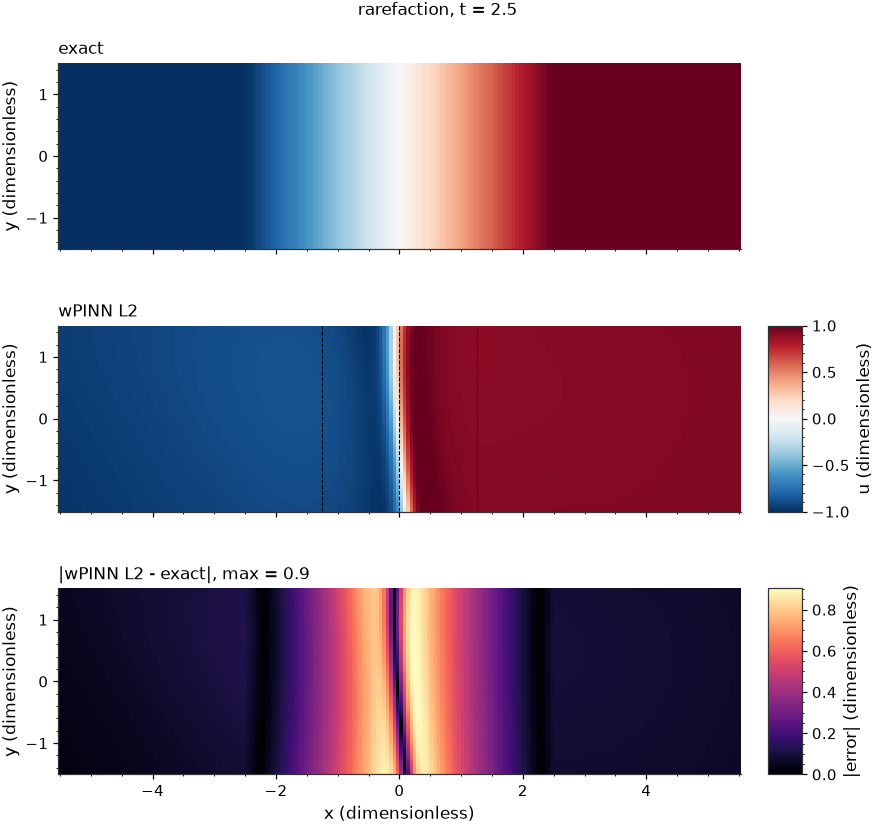

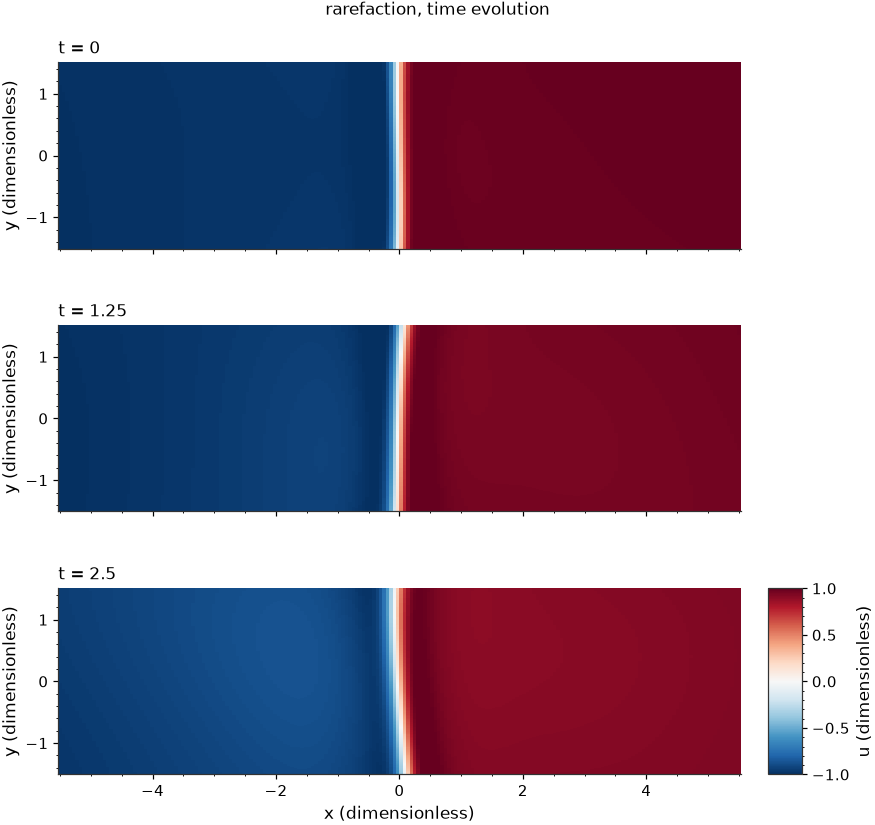

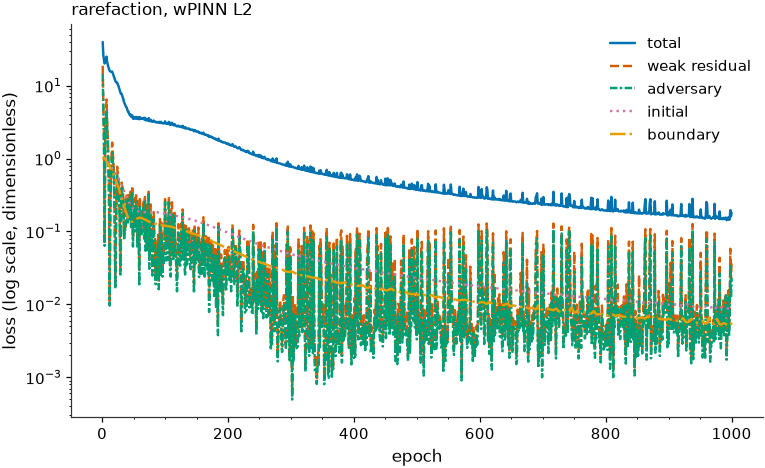

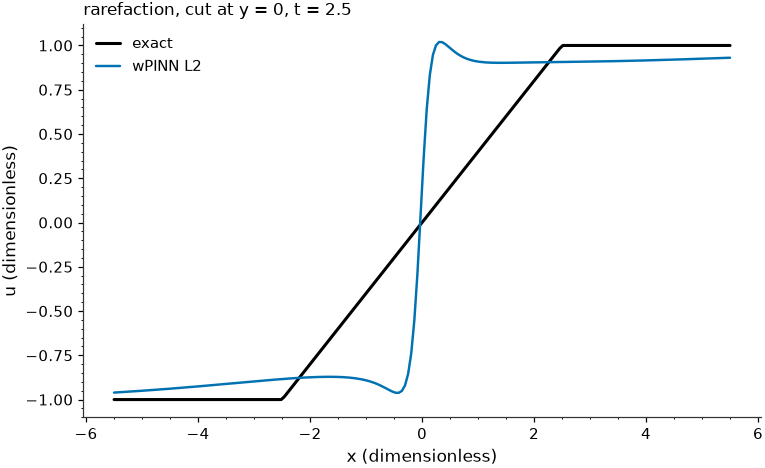

In [36]:
# La rarefacción es la prueba de la no unicidad. El dato -1 / +1 admite DOS
# soluciones débiles: el abanico u = x/t, que es la de entropía, y el choque de
# expansión, que deja el salto quieto en x = 0. La forma fuerte no distingue
# entre las dos. Con L0 sola el abanico sale con un salto residual en x = 0;
# aquí se mira si la difusión débil, sumada a la tasa de entropía, termina de
# abrirlo. El corte en y = 0 es donde se ve: abanico = rampa entre x = -T y
# x = T, choque de expansión = salto vertical.
rarefaction_run = run_weak_pinn_case(RAREFACTION_PROBLEM)
report_weak_pinn_run(rarefaction_run)
plot_profile_along_x([rarefaction_run], RAREFACTION_PROBLEM)
plt.show()

# Caso 2: choque móvil

=== moving_shock: wPINN L2, seed 0 ===


epoch    100  total 8.972e-01  weak 2.981e-02  adversary 1.443e-02  initial 5.263e-02  boundary 3.410e-02  [3 s]


epoch    200  total 3.970e-01  weak 7.624e-03  adversary 6.131e-03  initial 2.452e-02  boundary 1.442e-02  [5 s]


epoch    300  total 3.019e-01  weak 1.076e-02  adversary 9.388e-03  initial 1.806e-02  boundary 1.105e-02  [8 s]


epoch    400  total 2.313e-01  weak 3.425e-02  adversary 1.992e-02  initial 1.257e-02  boundary 7.143e-03  [10 s]


...

epoch    600  total 8.665e-02  weak 6.514e-03  adversary 5.487e-03  initial 5.148e-03  boundary 2.866e-03  [15 s]


epoch    700  total 7.227e-02  weak 9.248e-03  adversary 7.561e-03  initial 4.014e-03  boundary 2.288e-03  [18 s]


epoch    800  total 5.854e-02  weak 6.461e-03  adversary 4.837e-03  initial 3.312e-03  boundary 1.897e-03  [20 s]


epoch    900  total 5.246e-02  weak 8.933e-03  adversary 7.230e-03  initial 2.817e-03  boundary 1.536e-03  [23 s]


epoch   1000  total 4.155e-02  weak 2.885e-03  adversary 2.354e-03  initial 2.497e-03  boundary 1.369e-03  [26 s]
relative L1 = 0.2230   relative L2 = 0.4077   [26 s]


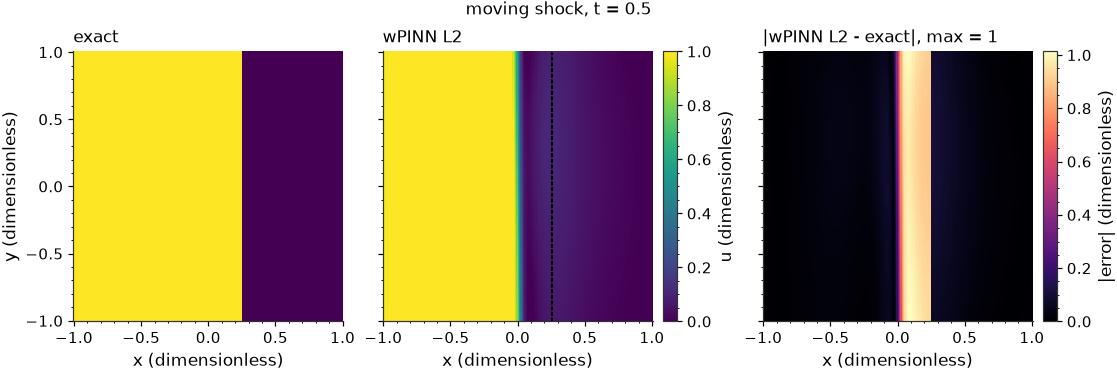

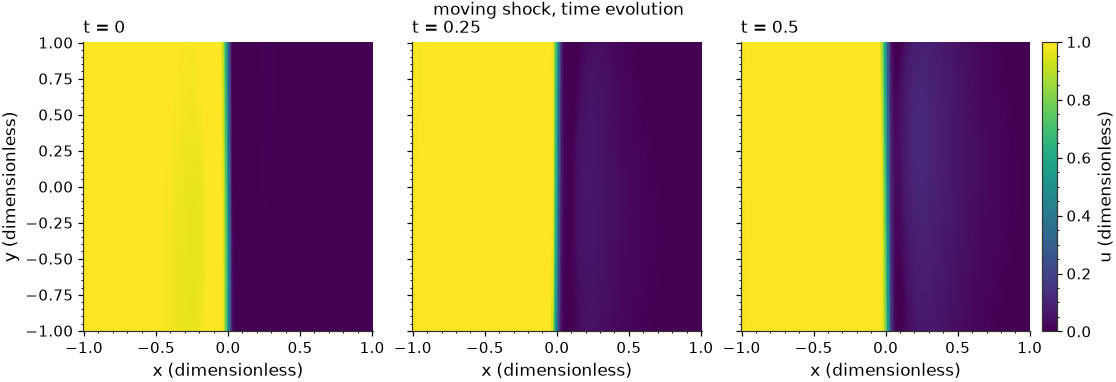

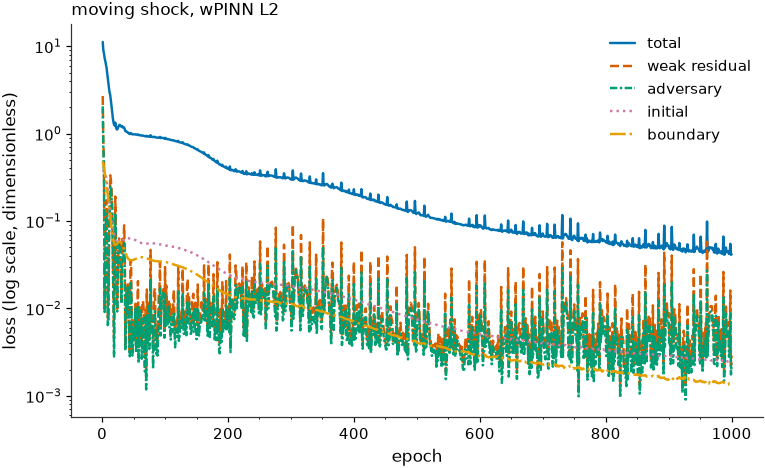

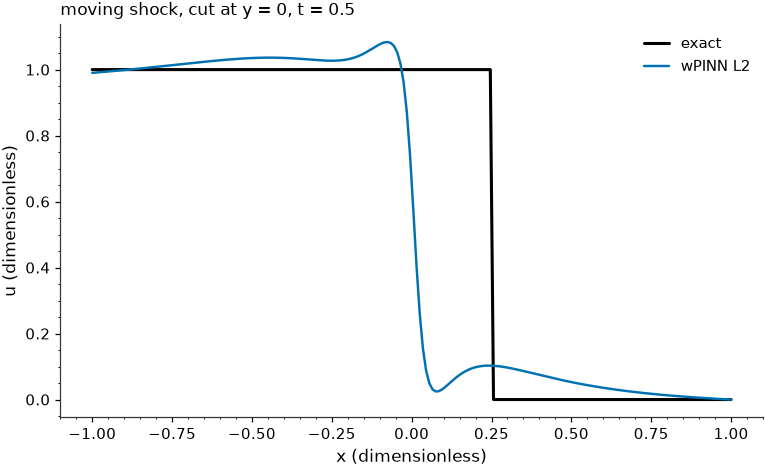

In [37]:
# El choque móvil es el caso sin ambigüedad: hay una sola solución débil, el
# salto viajando a la velocidad de Rankine-Hugoniot s = 1/2. Aquí no se mide si
# L2 elige bien, sino cuánto suaviza y cuánto retrasa el frente respecto de
# x = t/2. Es donde la difusión más puede estorbar: eps > 0 ensancha los choques
# a propósito, y este caso es todo choque.
moving_shock_run = run_weak_pinn_case(MOVING_SHOCK_PROBLEM)
report_weak_pinn_run(moving_shock_run)
plot_profile_along_x([moving_shock_run], MOVING_SHOCK_PROBLEM)
plt.show()

# Caso 3: Riemann 2D

=== riemann_2d: wPINN L2, seed 0 ===


epoch    100  total 5.259e+00  weak 2.176e-02  adversary 1.887e-02  initial 3.056e-01  boundary 2.181e-01  [3 s]


epoch    200  total 3.681e+00  weak 4.183e-02  adversary 3.553e-02  initial 2.321e-01  boundary 1.318e-01  [5 s]


epoch    300  total 2.977e+00  weak 4.076e-02  adversary 2.245e-02  initial 1.901e-01  boundary 1.035e-01  [8 s]


epoch    400  total 2.510e+00  weak 3.595e-02  adversary 2.015e-02  initial 1.633e-01  boundary 8.407e-02  [10 s]


...

epoch    600  total 1.865e+00  weak 5.688e-02  adversary 5.327e-02  initial 1.216e-01  boundary 5.925e-02  [15 s]


epoch    700  total 1.635e+00  weak 6.004e-02  adversary 5.610e-02  initial 1.062e-01  boundary 5.136e-02  [18 s]


epoch    800  total 1.421e+00  weak 5.986e-02  adversary 5.440e-02  initial 9.354e-02  boundary 4.258e-02  [20 s]


epoch    900  total 1.201e+00  weak 3.303e-02  adversary 2.789e-02  initial 7.940e-02  boundary 3.735e-02  [23 s]


epoch   1000  total 1.012e+00  weak 2.308e-02  adversary 1.819e-02  initial 6.759e-02  boundary 3.126e-02  [25 s]
no exact solution: errors not available   [25 s]


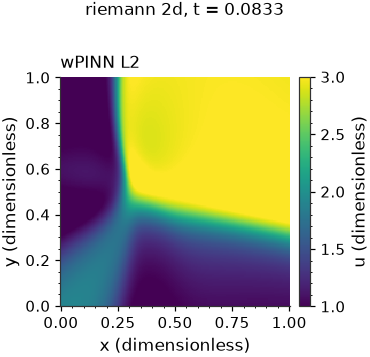

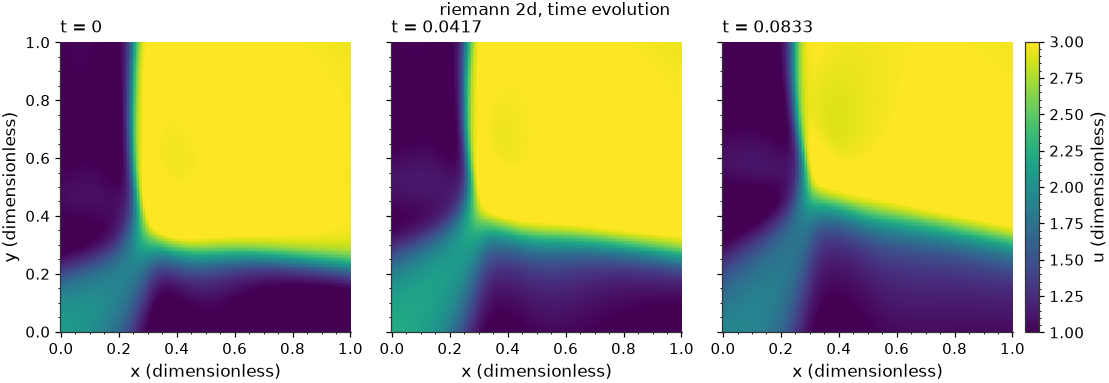

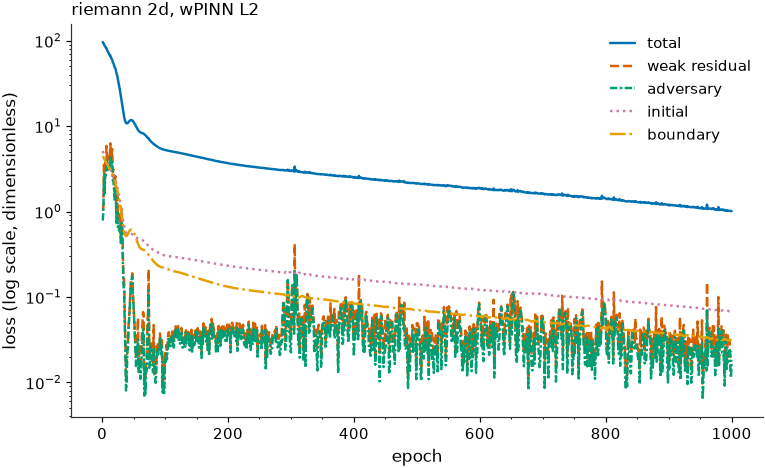

In [38]:
# El Riemann 2D es el caso genuinamente bidimensional y el único sin solución
# exacta: la tabla de errores queda vacía y el juicio es visual contra la
# figura 3 del paper. Lo que debe verse es la interacción de los tres estados
# alrededor de (0.25, 0.25). Con T = 1/12 y velocidad máxima H'(3) = 3 ninguna
# onda recorre más de 0.25, así que los frentes no deben tocar los bordes.
riemann_2d_run = run_weak_pinn_case(RIEMANN_2D_PROBLEM)
report_weak_pinn_run(riemann_2d_run)

# Resumen de las tres corridas

In [39]:
ALL_RUNS = [rarefaction_run, moving_shock_run, riemann_2d_run]


def report_all_runs(runs: Sequence[WeakPinnRun]) -> None:
    """One table with the errors at t = T and the cost of every run."""
    print(f"{'case':16s} {'loss':>6s} {'rel. L1':>9s} {'rel. L2':>9s} {'final total':>13s} {'seconds':>8s}")
    for run in runs:
        errors = run.final_time_errors
        # "-" y no 0.0 cuando no hay exacta: la celda está vacía por falta de
        # dato, y un cero se leería como un acierto perfecto.
        l1 = f"{errors['relative_l1']:9.4f}" if errors else f"{'-':>9s}"
        l2 = f"{errors['relative_l2']:9.4f}" if errors else f"{'-':>9s}"
        # Media de las últimas 100 épocas y no el último valor: el juego min-max
        # hace saltar la pérdida de época en época y una sola puede ser afortunada.
        final_total_loss = float(np.mean(run.history.total[-100:]))
        print(f"{run.problem.name:16s} {run.label:>6s} {l1} {l2} {final_total_loss:13.4e} {run.training_seconds:8.0f}")


report_all_runs(ALL_RUNS)

case               loss   rel. L1   rel. L2   final total  seconds
rarefaction      wPINN L2    0.2833    0.3905    1.6605e-01       27
moving_shock     wPINN L2    0.2230    0.4077    4.8229e-02       26
riemann_2d       wPINN L2         -         -    1.1069e+00       25


# Qué sigue: comparar con L0 y con L1, y variar epsilon

Los tres niveles están en el notebook y sólo se corrió L2. Para comparar:

```python
rarefaction_l0 = run_weak_pinn_case(RAREFACTION_PROBLEM, residual_level=0)
rarefaction_l1 = run_weak_pinn_case(RAREFACTION_PROBLEM, residual_level=1)
plot_profile_along_x([rarefaction_l0, rarefaction_l1, rarefaction_run], RAREFACTION_PROBLEM)
```

`plot_profile_along_x` acepta varias corridas en el mismo eje, así que esa
última línea es la figura que contesta la pregunta del paper: si la tasa de
entropía de L1 o la difusión de L2 corrigen lo que L0 deja mal en la
rarefacción.

El experimento propio de L2 es **barrer epsilon**, porque es el único nivel que
lo usa. La solución de entropía es el límite cuando epsilon tiende a cero, así
que hay un compromiso: mucha difusión suaviza los choques, poca no selecciona
nada.

```python
for diffusion_coefficient in (1e-4, 1e-3, 1e-2):
    budget = replace(PAPER_WEAK_BUDGET, diffusion_coefficient=diffusion_coefficient)
    run = run_weak_pinn_case(RAREFACTION_PROBLEM, budget=budget)
    print(diffusion_coefficient, run.final_time_errors)
```

Otras dos cosas que el notebook deja preparadas pero no ejecuta:

- **Cambiar la función test.** `TestFunctionNetwork` recibe `range_transform` y
  `window` como argumentos. `positive_by_square` en vez de
  `positive_by_softplus`, o `sine_bump_window` en vez de la polinómica, son
  cambios de una palabra.
- **Cambiar la agregación sobre $c$.** `aggregate_over_constants(..., mode="mean")`
  en vez de `"max"`. En los experimentos 1D el promedio rompía el choque; vale la
  pena ver si en 2D pasa lo mismo.